# Common word Analysis - full data, defferences between coditions?

this script:
- reads the processed data
- builds a string with all user replies per condition
- analyses the most common words in the user replies per condition. What are common themes?

In [1]:
# packages
import pandas as pd
import numpy as np
import re
from collections import Counter
from nltk.corpus import stopwords
import nltk
from nltk.util import bigrams
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import networkx as nx
from itertools import combinations
from collections import defaultdict

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /Users/ella/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [2]:
# helper
stop_words = set(stopwords.words("english"))
custom_stopwords = {"vaccinations", "vaccines", "vaccine", "vaccination", "climate", "change", "inequality", "tax", "taxes"} # words that are common but do not give additional info
stop_words = stop_words.union(custom_stopwords)

def clean_text(text):
    text = text.lower() # making all text lower case
    text = re.sub(r"[^a-z\s]", "", text)  # remove punctuation/numbers, only keep letters
    words = text.split() # split all single words 
    words = [w for w in words if w not in stop_words] # remove all words that are in stopwords list
    return words



# build network graph
def build_cooccurrence_network(words, window=2, min_edge_weight=5): 
    cooc = defaultdict(int)
    for i, w1 in enumerate(words):
        for w2 in words[i+1 : i+window+1]:
            if w1 != w2:
                pair = tuple(sorted([w1, w2]))
                cooc[pair] += 1
    G = nx.Graph()
    for (w1, w2), weight in cooc.items():
        if weight >= min_edge_weight:
            G.add_edge(w1, w2, weight=weight)
    return G

def plot_cooccurrence_network(G, title="", top_n=40):
    
    # 1. Auf top-N Knoten nach Degree reduzieren
    top_nodes = sorted(G.degree, key=lambda x: x[1], reverse=True)[:top_n]
    G = G.subgraph([n for n, _ in top_nodes]).copy()
    
    # 2. Isolierte Knoten entfernen
    G.remove_nodes_from(list(nx.isolates(G)))
    
    if len(G.nodes) == 0:
        print(f"No edges above threshold for: {title}")
        return

    # 3. Community Detection für Farben
    communities = nx.community.greedy_modularity_communities(G)
    color_map = {}
    colors = plt.cm.tab10.colors
    for i, community in enumerate(communities):
        for node in community:
            color_map[node] = colors[i % len(colors)]
    node_colors = [color_map[n] for n in G.nodes]

    # 4. Besseres Layout
    centrality = nx.degree_centrality(G)
    node_sizes = [centrality[n] * 3000 + 200 for n in G.nodes]
    weights = [G[u][v]['weight'] for u, v in G.edges]
    max_w = max(weights) if weights else 1
    edge_widths = [3 * w / max_w for w in weights]

    pos = nx.kamada_kawai_layout(G, weight='weight')  
    
    plt.figure(figsize=(14, 10))
    nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color=node_colors, alpha=0.85)
    nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold')
    nx.draw_networkx_edges(G, pos, width=edge_widths, alpha=0.4, edge_color='gray')
    plt.title(title, fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

In [3]:
# reading data 
df = pd.read_csv("../orig_data/data_analysis_AI_dialogue_study.csv")

In [4]:
# concatenating all reply columns into one column and dict with an entry per condition (over all participants)
reply_cols = ["userFirstReply", "userSecondReply", "userThirdReply"]
df["all_replies"] = df[reply_cols].fillna("").agg(" ".join, axis=1)

# building one corpus (i.e. list) per intervention condition
corpus = {}

for topic in df["condition"].unique():
    
    texts = df.loc[df["condition"] == topic, "all_replies"]
    
    combined_text = " ".join(texts)
    
    corpus[topic] = clean_text(combined_text)

In [5]:
# extracting the most common words per condition
top_words = {}
bigram_corpus = {}

print("Most common words and bigrams per condition: ")
for topic, words in corpus.items():

    bigram_list = [" ".join(b) for b in bigrams(words)]
    bigram_corpus[topic] = bigram_list
    
    counter = Counter(words)
    bigram_counts = Counter(bigram_corpus[topic])

    top_words[topic] = counter.most_common(10)

    print("\n", topic)
    print(counter.most_common(10))
    print(bigram_counts.most_common(10))


Most common words and bigrams per condition: 

 vacc_bel+pol
[('school', 498), ('children', 393), ('think', 384), ('dont', 282), ('covid', 273), ('would', 272), ('people', 251), ('great', 247), ('vaccinated', 237), ('agree', 225)]
[('great great', 200), ('school entry', 77), ('side effects', 53), ('children vaccinated', 51), ('requirement school', 34), ('medical exemptions', 33), ('dont think', 33), ('would like', 32), ('dont need', 31), ('school age', 25)]

 vacc_bel
[('covid', 379), ('think', 378), ('people', 352), ('get', 327), ('dont', 281), ('would', 205), ('believe', 179), ('vaccinated', 178), ('need', 175), ('agree', 174)]
[('side effects', 87), ('get vaccinated', 34), ('dont need', 34), ('flu shot', 34), ('covid shot', 33), ('would like', 30), ('dont trust', 30), ('get flu', 29), ('long term', 26), ('safe effective', 26)]

 vacc_pol
[('school', 545), ('think', 473), ('children', 459), ('would', 349), ('vaccinated', 289), ('agree', 269), ('dont', 241), ('kids', 216), ('parents',

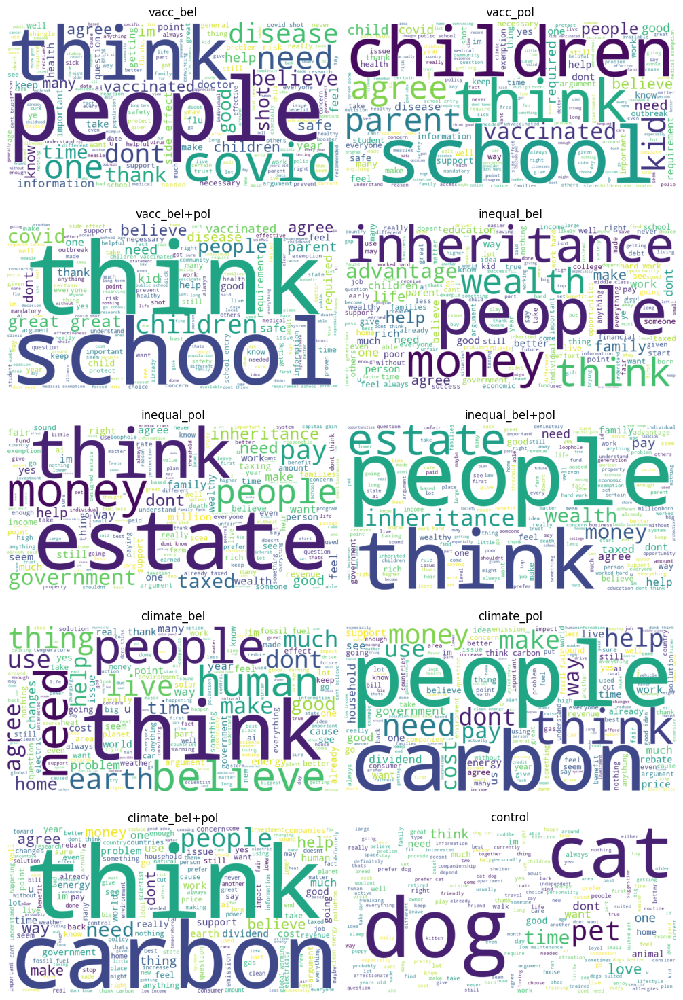

In [6]:
order = [
    "vacc_bel", "vacc_pol", "vacc_bel+pol",
    "inequal_bel", "inequal_pol", "inequal_bel+pol",
    "climate_bel", "climate_pol", "climate_bel+pol",
    "control"
]

fig, axes = plt.subplots(
    5, 
    2,
    figsize=(10, 15)
)

axes = axes.flatten() 

for i, topic in enumerate(order):
    words = corpus[topic]
    text = " ".join(words)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        relative_scaling=1,
        collocations=True,
        random_state=42
    ).generate(text)

    ax = axes[i]
    ax.imshow(wordcloud, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(topic)

plt.tight_layout(pad=0.5)
plt.savefig("figures/combined-wordcloud.pdf", dpi=400)
plt.show()

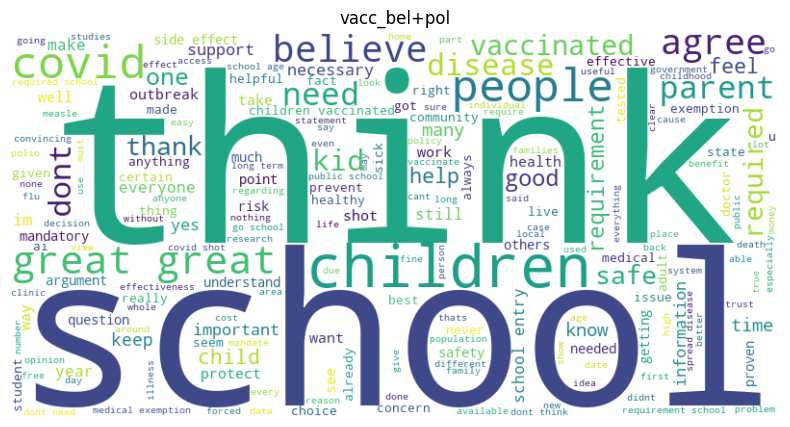

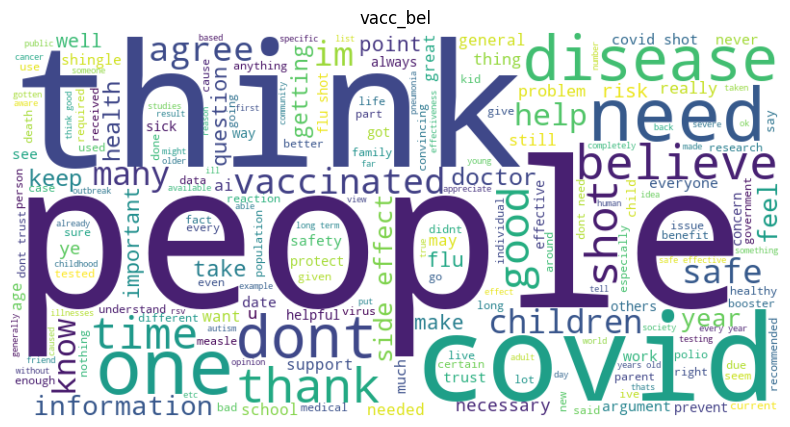

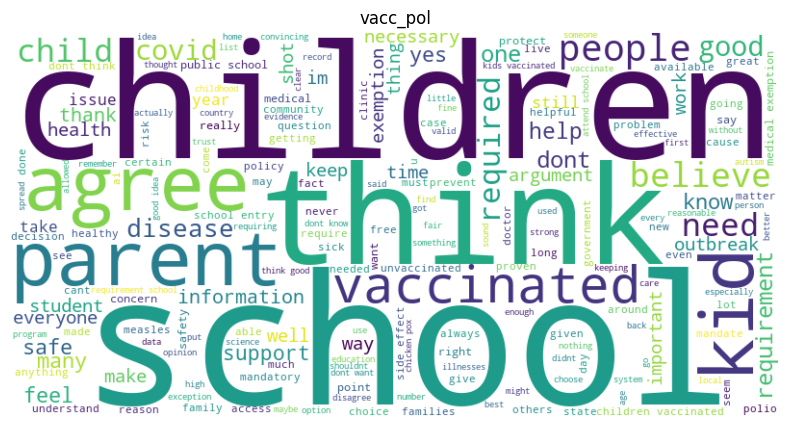

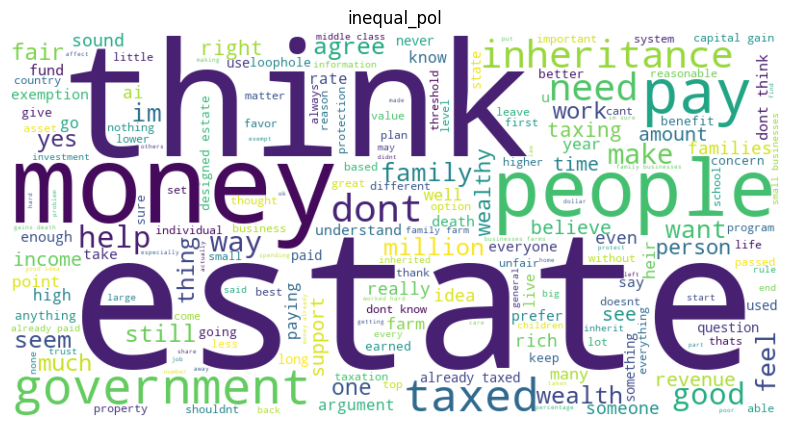

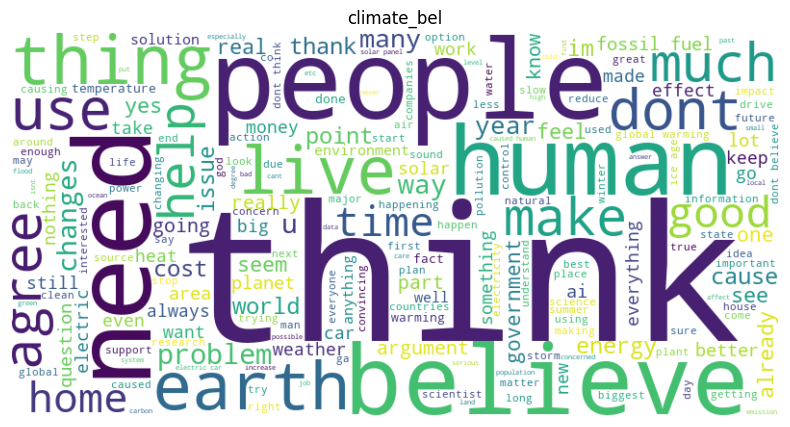

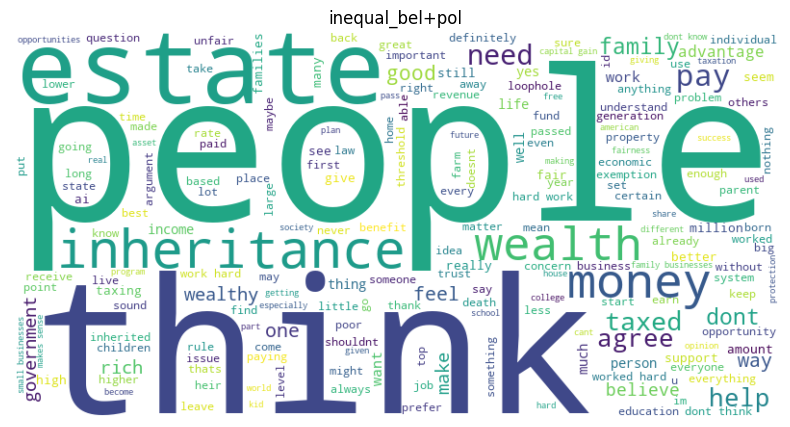

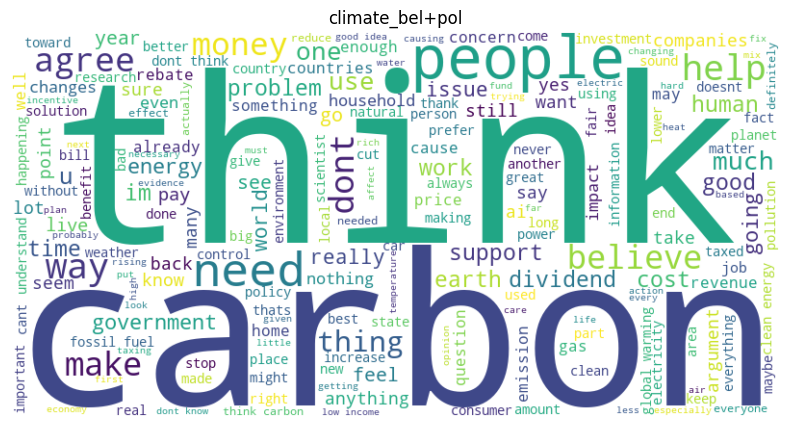

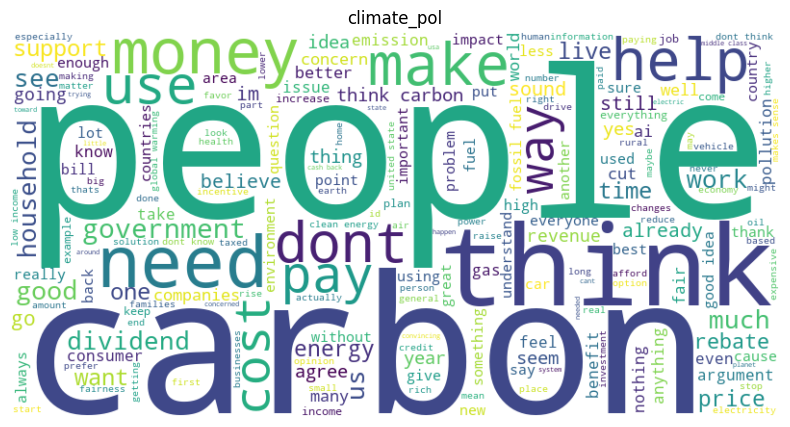

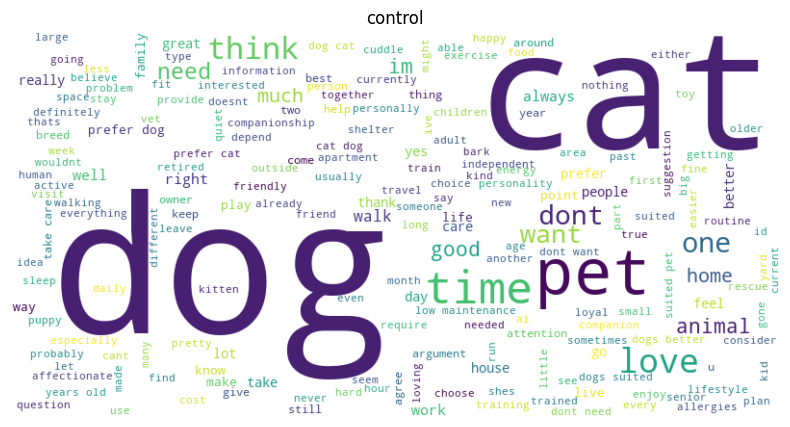

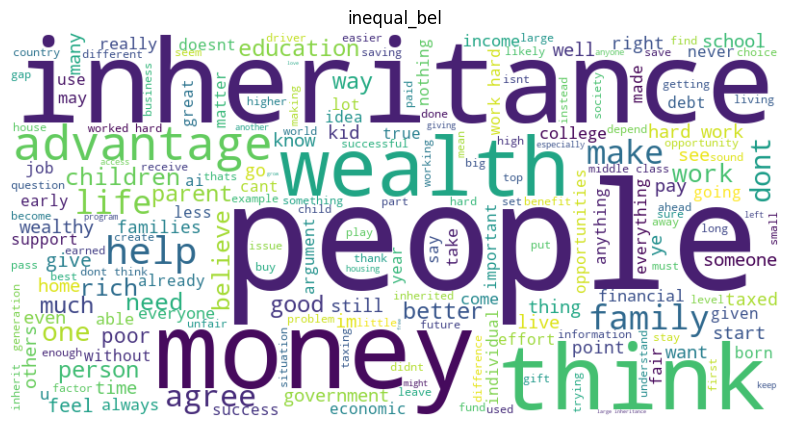

In [7]:
# creating a wordcloud per condition
for topic, words in corpus.items():

    text = " ".join(words)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        relative_scaling = 1,
        collocations =  True,
        random_state=42
    ).generate(text)

    plt.figure(figsize=(10,5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(topic)
    plt.savefig(f"figures/{topic}-wordcloud.pdf", dpi=400)
    plt.show()


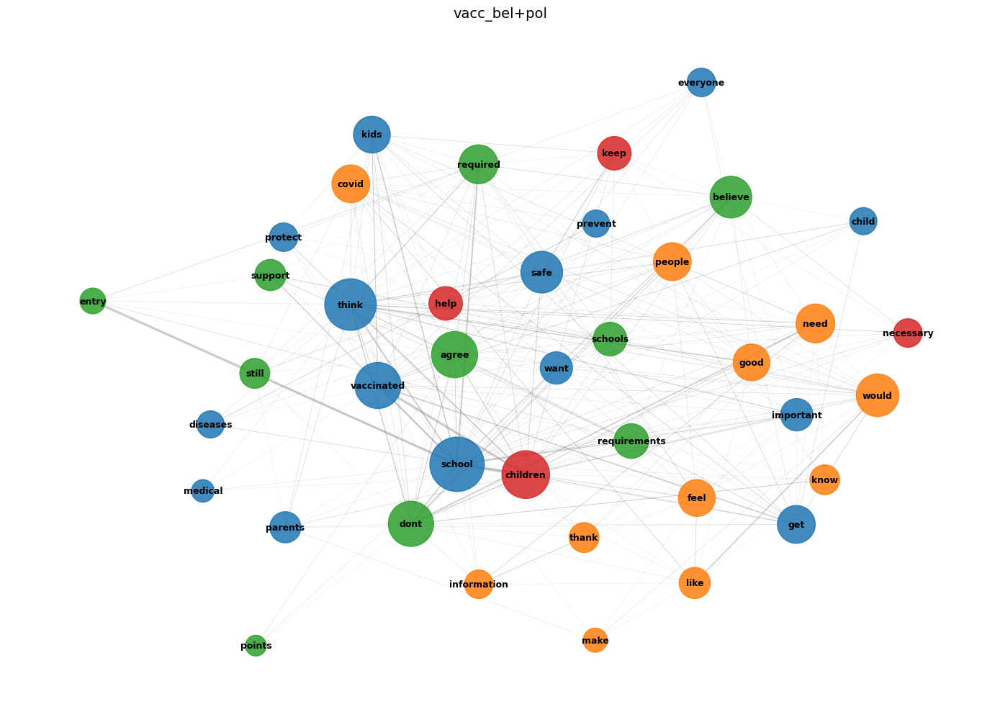

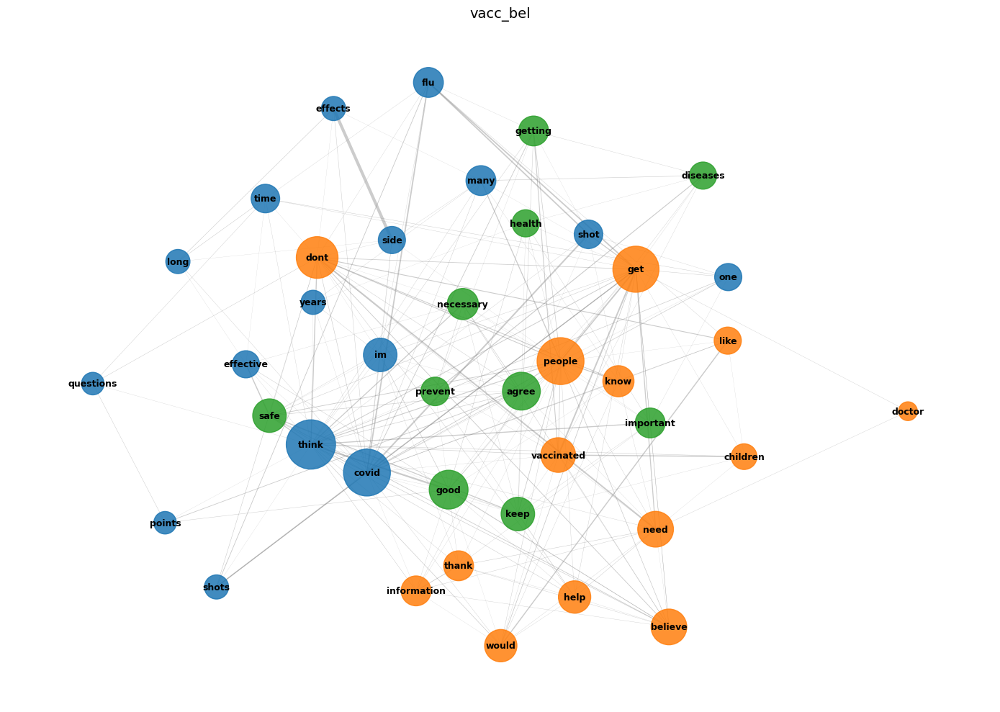

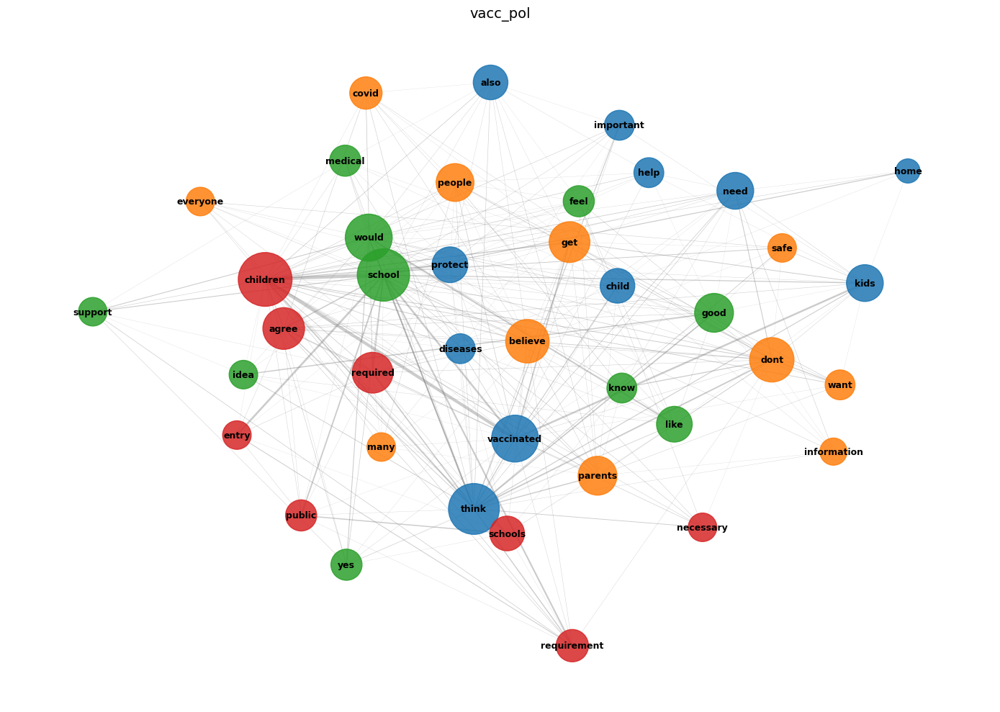

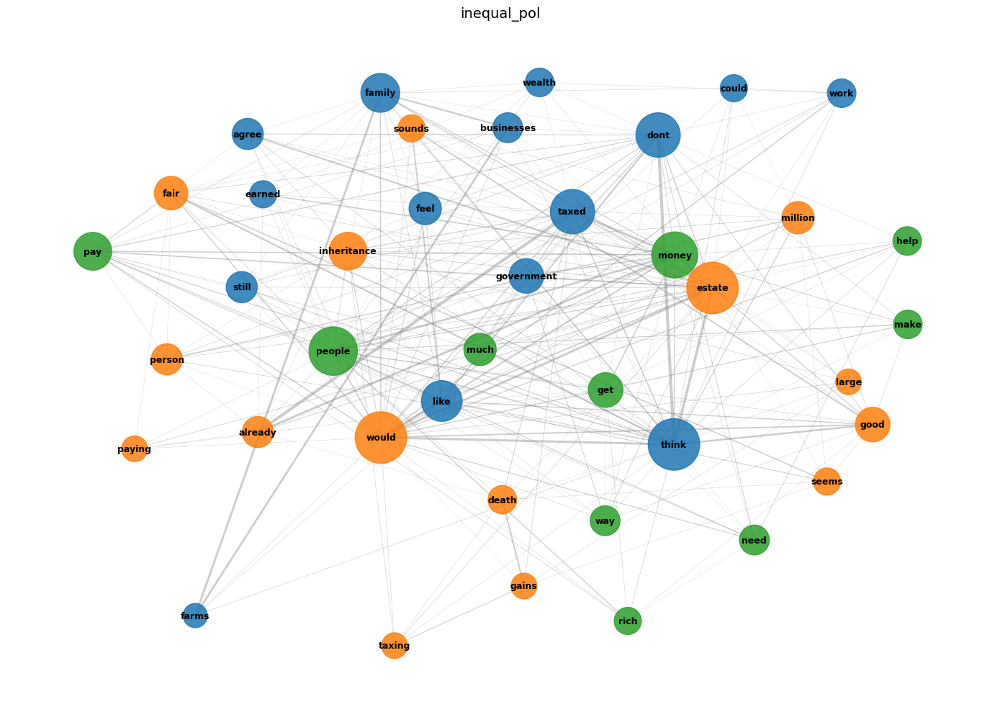

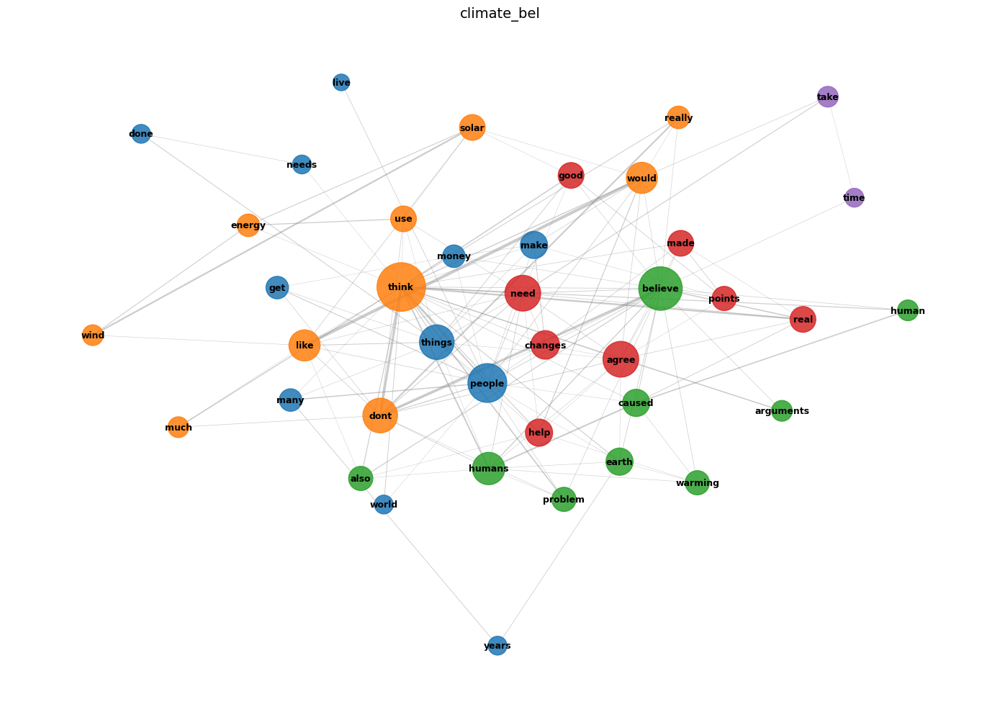

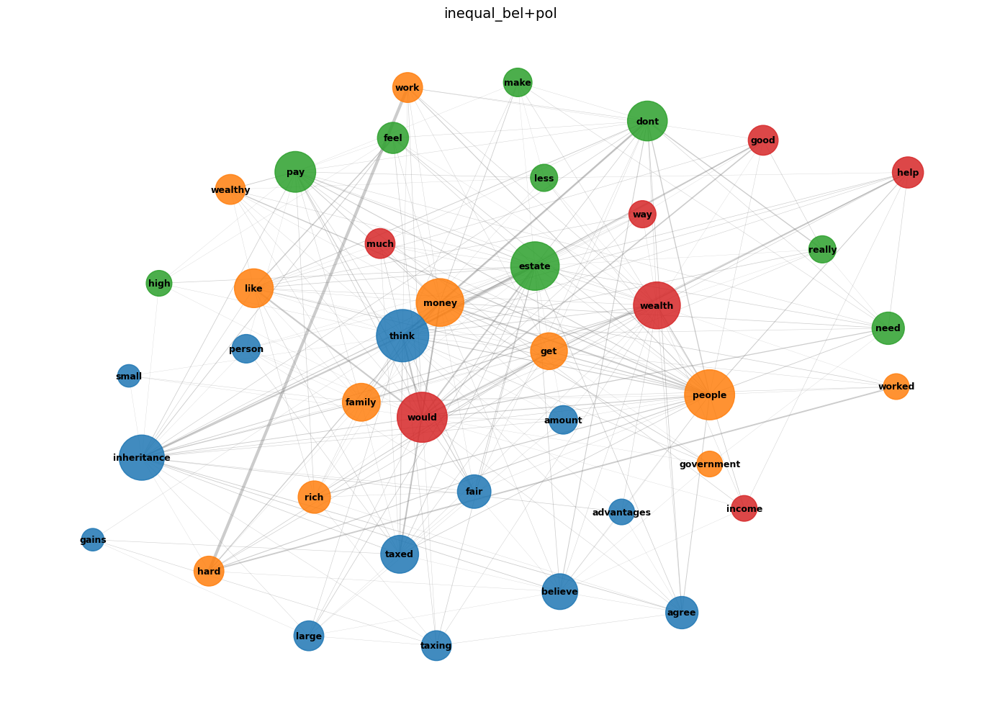

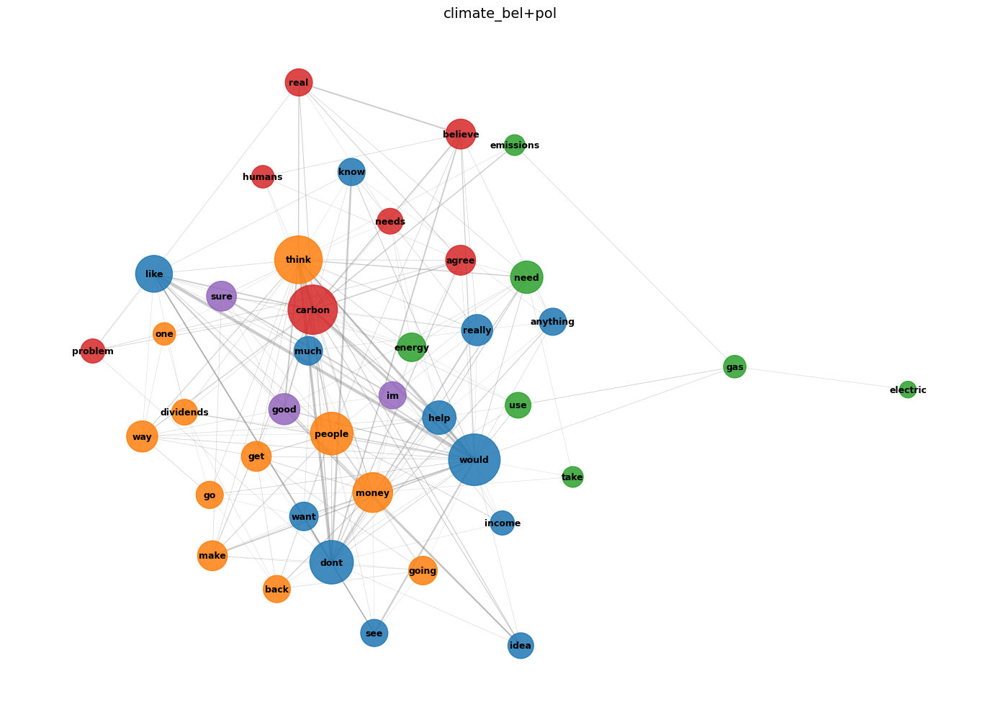

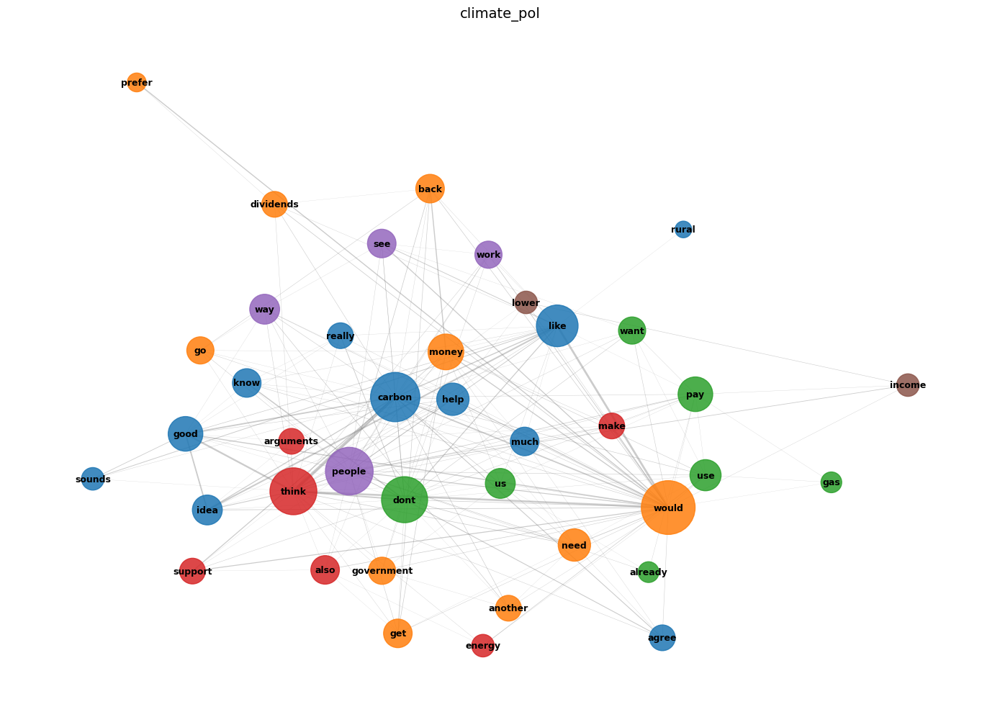

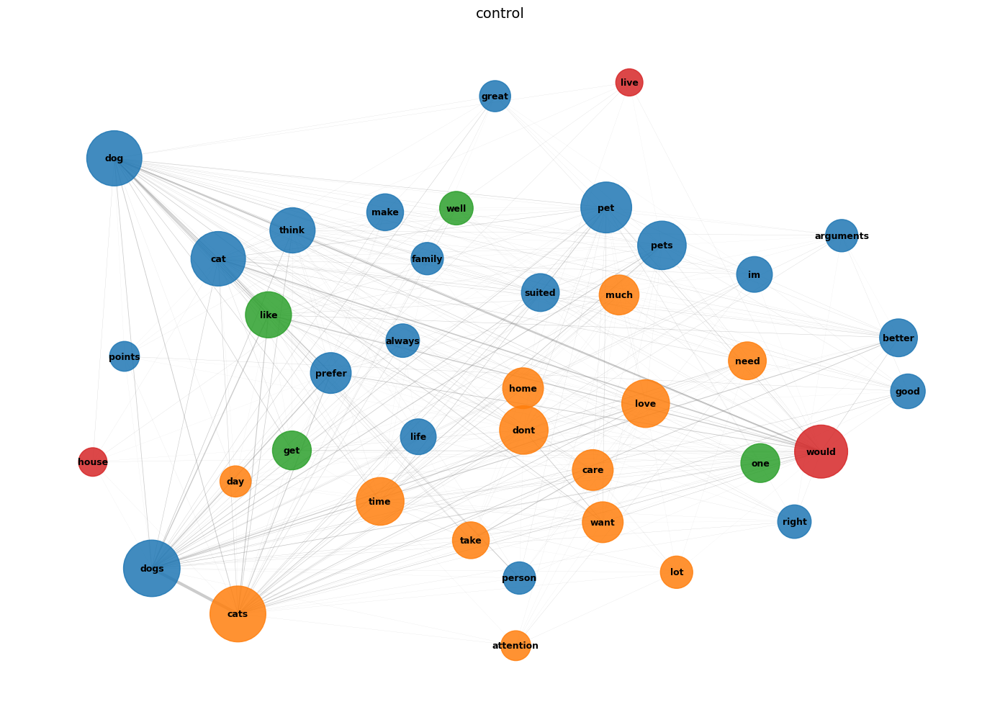

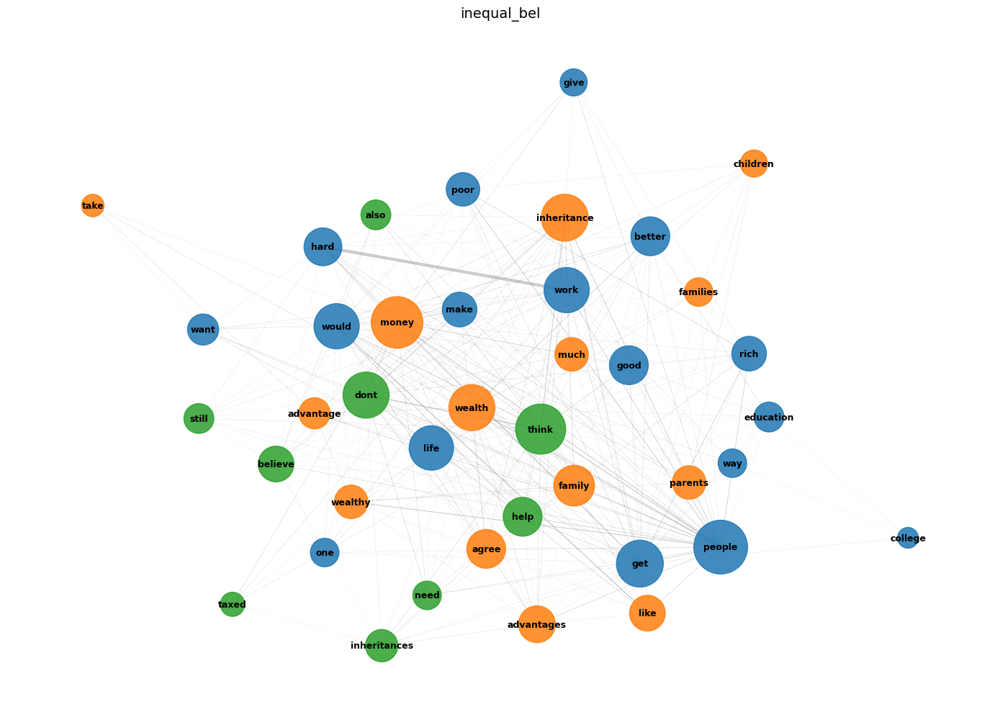

In [8]:
# building network graph
for topic, words in corpus.items():
    G = build_cooccurrence_network(words, window=2, min_edge_weight=5)
    plot_cooccurrence_network(G, title=topic)

## Erklärung

Größe eines Knotens = Degree Centrality — wie viele andere Wörter dieses Wort direkt co-occuriert. Große Knoten sind thematische Hubs.

Farbe = Community (Greedy Modularity) — Wörter gleicher Farbe bilden eine Gruppe, die untereinander häufiger zusammen auftreten als mit dem Rest des Graphen. Interpretierbar als latente Subthemen.

Nähe = kamada_kawai_layout minimiert eine Energiefunktion basierend auf Graphdistanz: Wörter, die durch viele starke Kanten verbunden sind, landen näher beieinander. Nähe ≈ häufige direkte oder indirekte Co-Occurrence. (direkt: sie kommen häufiger als 5 mal zusammen vor, indirekt: ein anderes Wort kommt häufig mit beiden zusammen vor, dadurch nah beieinander)

Kantendicke = absolute Co-Occurrence-Häufigkeit im definierten Fenster.

## Distinctive Words per condition 

In [9]:
# collecting frequencies per condition - helpers

# word counts and total number of words per condition
topic_word_counts = {}
topic_totals = {}

for topic, words in corpus.items():

    counts = Counter(words)

    topic_word_counts[topic] = counts
    topic_totals[topic] = sum(counts.values())

# only use words that appear more than five times per topic (handling rare occurences issue)
for topic in topic_word_counts:
    topic_word_counts[topic] = {w: c for w, c in topic_word_counts[topic].items() if c >= 5}

#computing relative frequencies
all_words = set()

for counts in topic_word_counts.values():
    all_words.update(counts.keys())

rows = []

for word in all_words:

    row = {"word": word}

    for topic in topic_word_counts:

        freq = topic_word_counts[topic].get(word, 0)
        total = topic_totals[topic]

        row[topic] = freq / total

    rows.append(row)

freq_df = pd.DataFrame(rows)

In [10]:
def compute_distinctiveness(freq_df, topic_cols):
    """
    Transform relative-frequency DataFrame into per-condition distinctiveness scores.
    """
    df = freq_df.set_index('word')[topic_cols].copy().astype(float)
    result = pd.DataFrame(index=df.index, columns=topic_cols, dtype=float)

    for col in topic_cols:
        others_mean = df.drop(columns=col).mean(axis=1)
        result[col] = df[col] / others_mean.replace(0, np.nan)

    return result.reset_index()


# Usage
topic_cols = [c for c in freq_df.columns if c != 'word']
distinct_df = compute_distinctiveness(freq_df, topic_cols)

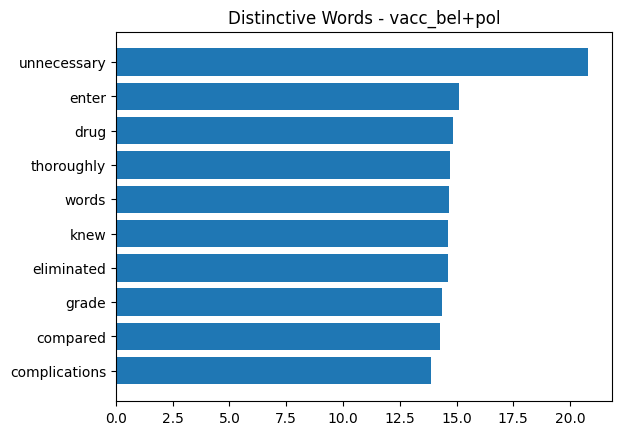

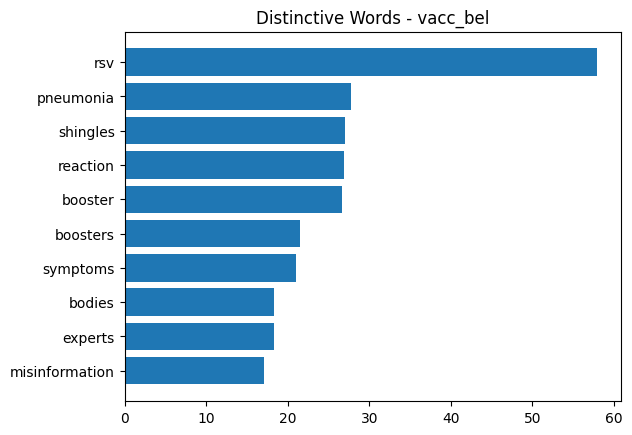

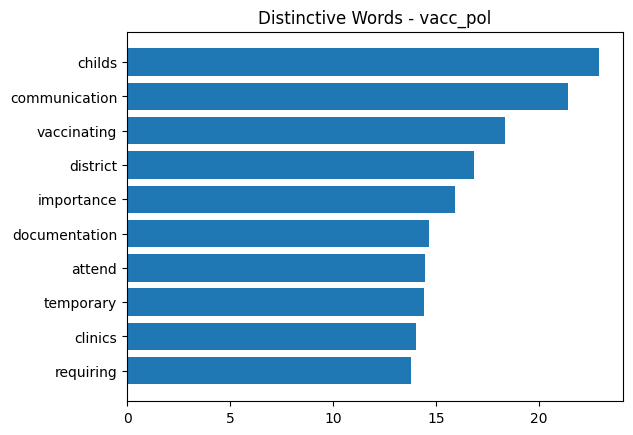

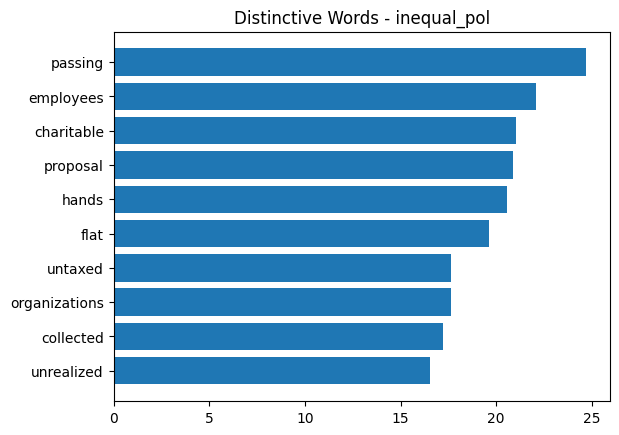

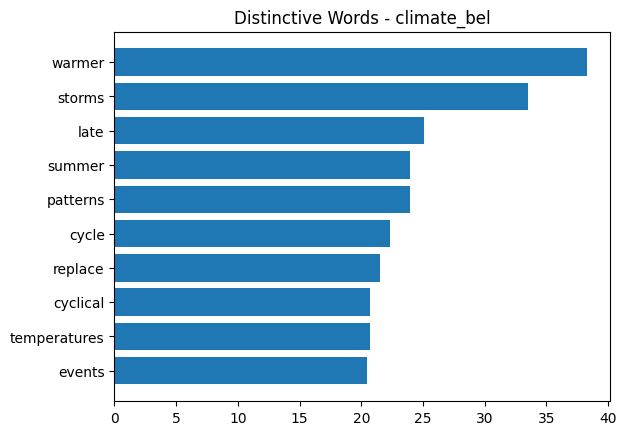

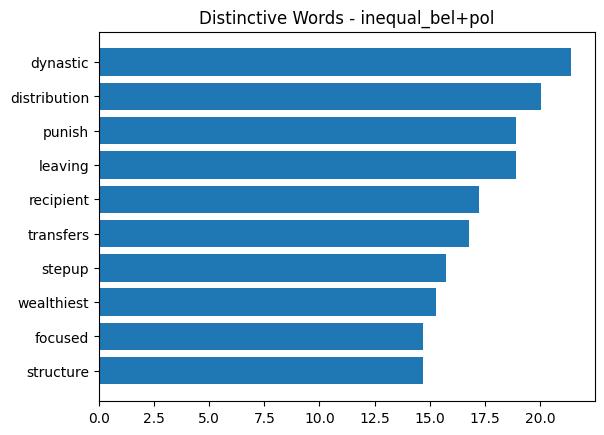

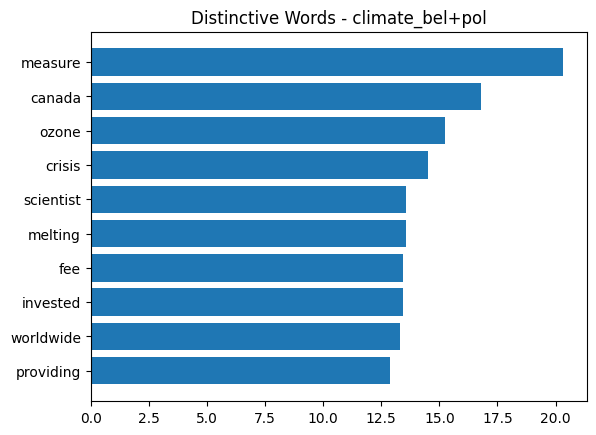

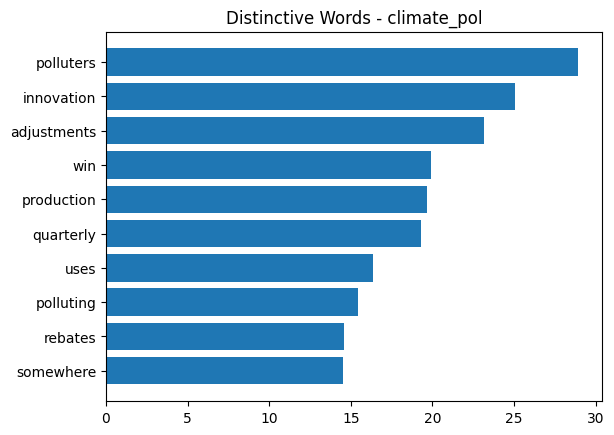

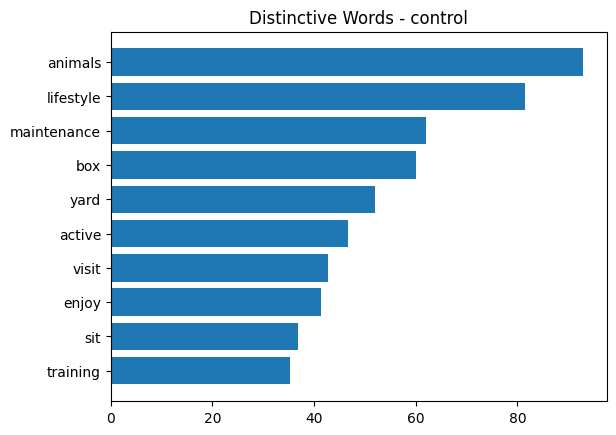

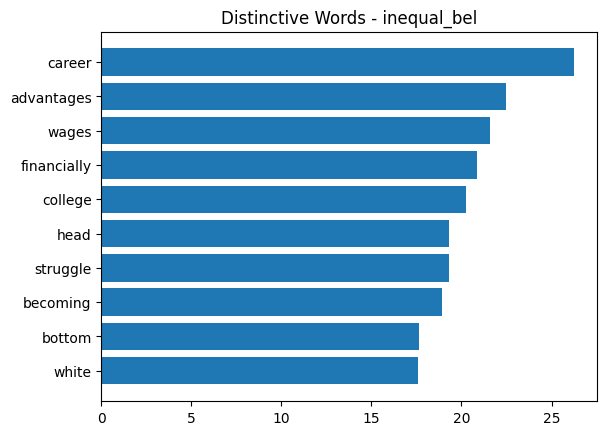

In [11]:
# show words that are relatively frequent (compared to the other conditions)
for col in topic_cols:
        
    top = distinct_df.sort_values(col, ascending=False).head(10)

    plt.barh(top["word"], top[col])
    plt.title(f"Distinctive Words - {col}")
    plt.gca().invert_yaxis()
    plt.show()

# Analysis of Subgroup: Participants with large pre-post differences

In [12]:
# dictionary to bring condition and interesting diff column together
condition_effect_dict = {
'vacc_bel+pol': ['diff_vacc_bel', 'diff_vacc_pol'],
'vacc_bel': ['diff_vacc_bel'],
'vacc_pol': ['diff_vacc_pol'],
'inequal_pol': ['diff_ineq_pol'],
'climate_bel': ['diff_clim_bel'],
'inequal_bel+pol': ['diff_ineq_pol', 'diff_ineq_bel'],
'climate_bel+pol': ['diff_clim_bel', 'diff_clim_pol'],
'climate_pol': ['diff_clim_pol'],
'control': None,
'inequal_bel': ['diff_ineq_bel']
}

# subset df with big effects
def has_big_effect(row, condition_effect_dict, threshold=8):
    condition = row['condition']
    cols = condition_effect_dict.get(condition)
    if cols is None:
        return False
    return any(row[col] >= threshold for col in cols)

mask = df.apply(has_big_effect, axis=1, condition_effect_dict=condition_effect_dict)
subset_df_big_effects = df[mask].copy()

In [13]:
len(subset_df_big_effects)

1825

In [14]:
# building one corpus (i.e. list) per intervention condition
corpus = {}

for topic in subset_df_big_effects["condition"].unique():
    
    texts = subset_df_big_effects.loc[subset_df_big_effects["condition"] == topic, "all_replies"]
    
    combined_text = " ".join(texts)
    
    corpus[topic] = clean_text(combined_text)

In [15]:
# extracting the most common words per condition
top_words = {}
bigram_corpus = {}

print("Most common words and bigrams per condition: ")
for topic, words in corpus.items():

    bigram_list = [" ".join(b) for b in bigrams(words)]
    bigram_corpus[topic] = bigram_list
    
    counter = Counter(words)
    bigram_counts = Counter(bigram_corpus[topic])

    top_words[topic] = counter.most_common(10)

    print("\n", topic)
    print(counter.most_common(10))
    print(bigram_counts.most_common(10))


Most common words and bigrams per condition: 

 inequal_pol
[('would', 291), ('estate', 195), ('think', 195), ('people', 124), ('money', 119), ('like', 118), ('dont', 99), ('good', 97), ('pay', 86), ('taxed', 85)]
[('dont think', 22), ('would like', 18), ('designed estate', 17), ('like idea', 16), ('good idea', 15), ('million per', 14), ('family business', 14), ('im sure', 14), ('united states', 13), ('would support', 13)]

 inequal_bel+pol
[('would', 247), ('think', 233), ('people', 213), ('estate', 176), ('wealth', 159), ('money', 150), ('inheritance', 133), ('like', 121), ('family', 114), ('dont', 110)]
[('dont think', 22), ('family businesses', 21), ('capital gains', 15), ('small businesses', 14), ('hard work', 14), ('makes sense', 13), ('sounds like', 13), ('work hard', 13), ('already taxed', 13), ('would need', 13)]

 vacc_bel
[('think', 83), ('covid', 78), ('get', 56), ('people', 53), ('dont', 53), ('like', 44), ('health', 36), ('believe', 35), ('one', 34), ('flu', 30)]
[('side 

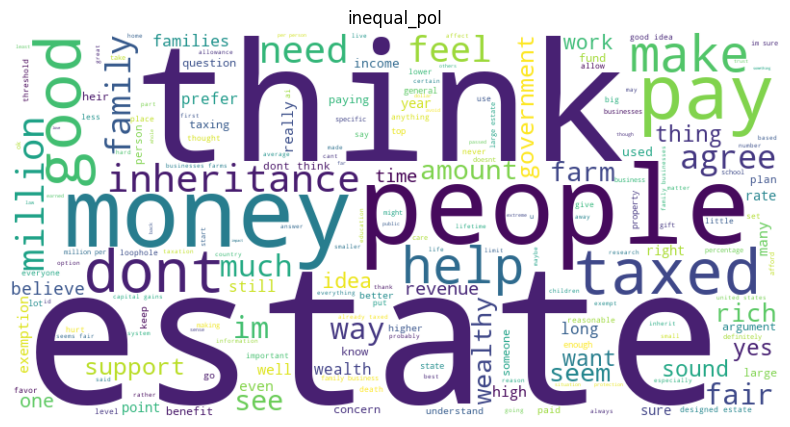

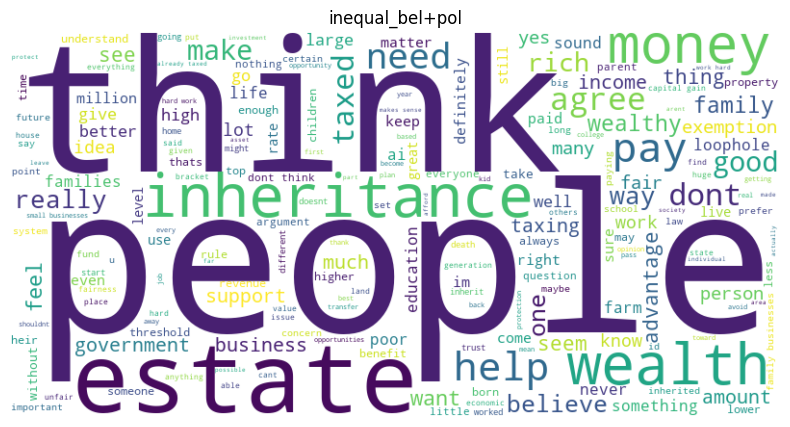

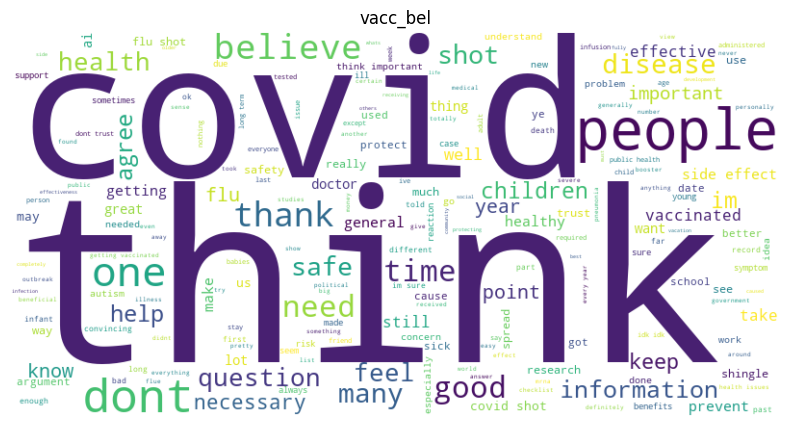

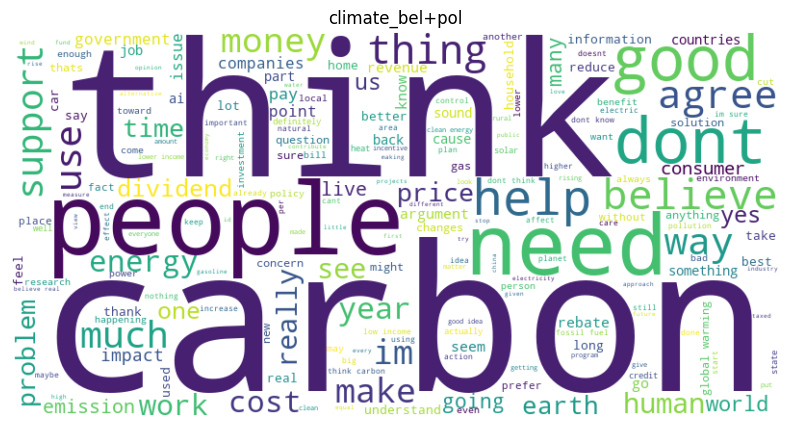

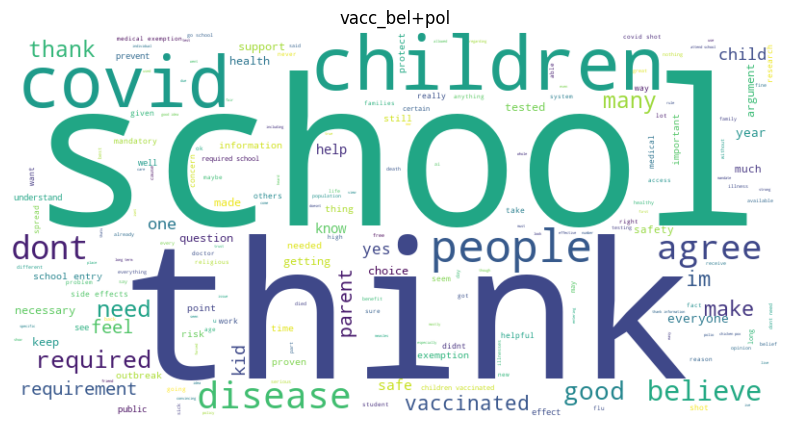

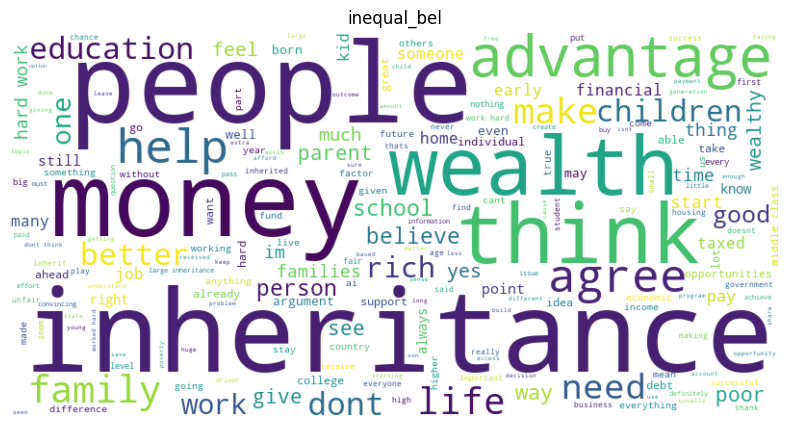

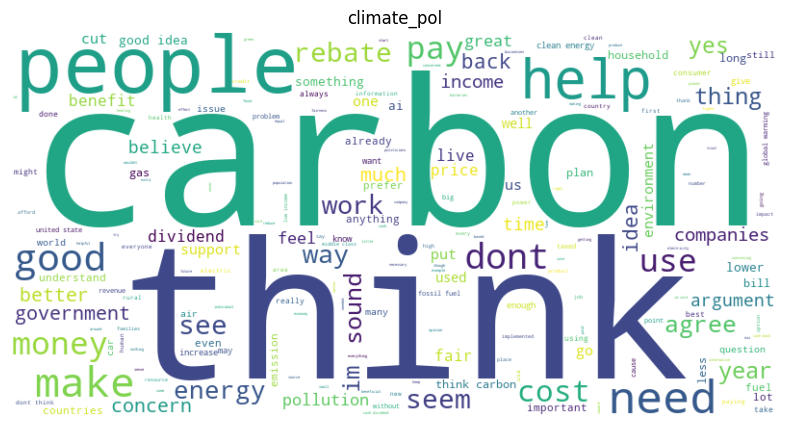

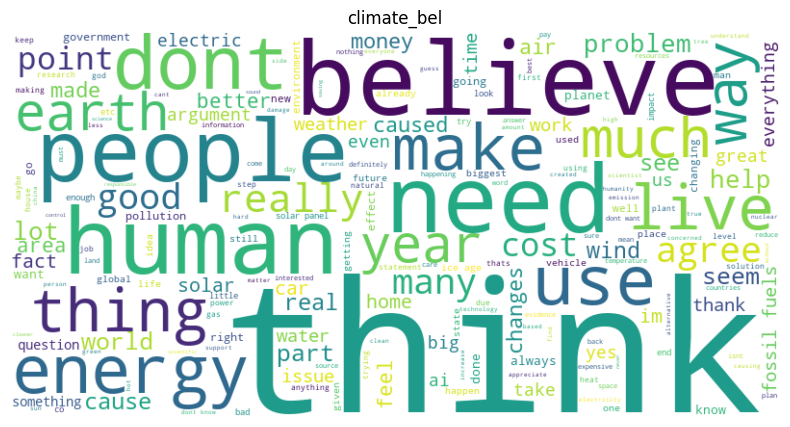

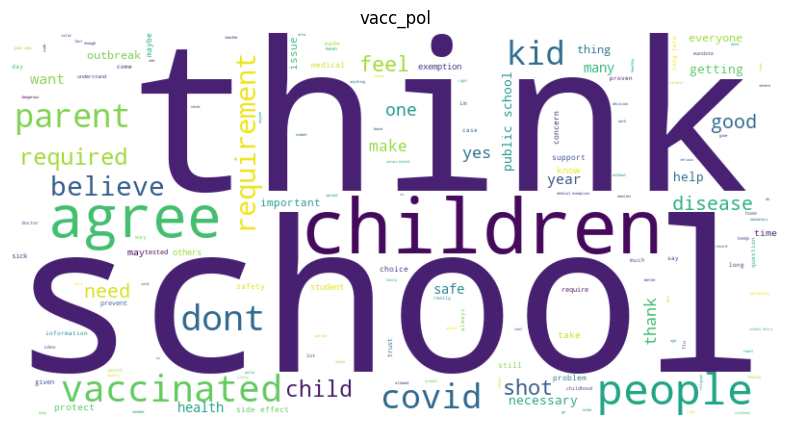

In [16]:
# creating a wordcloud per condition
for topic, words in corpus.items():

    text = " ".join(words)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        relative_scaling = 1,
        collocations =  True,
        random_state=42
    ).generate(text)

    plt.figure(figsize=(10,5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(topic)
    plt.show()

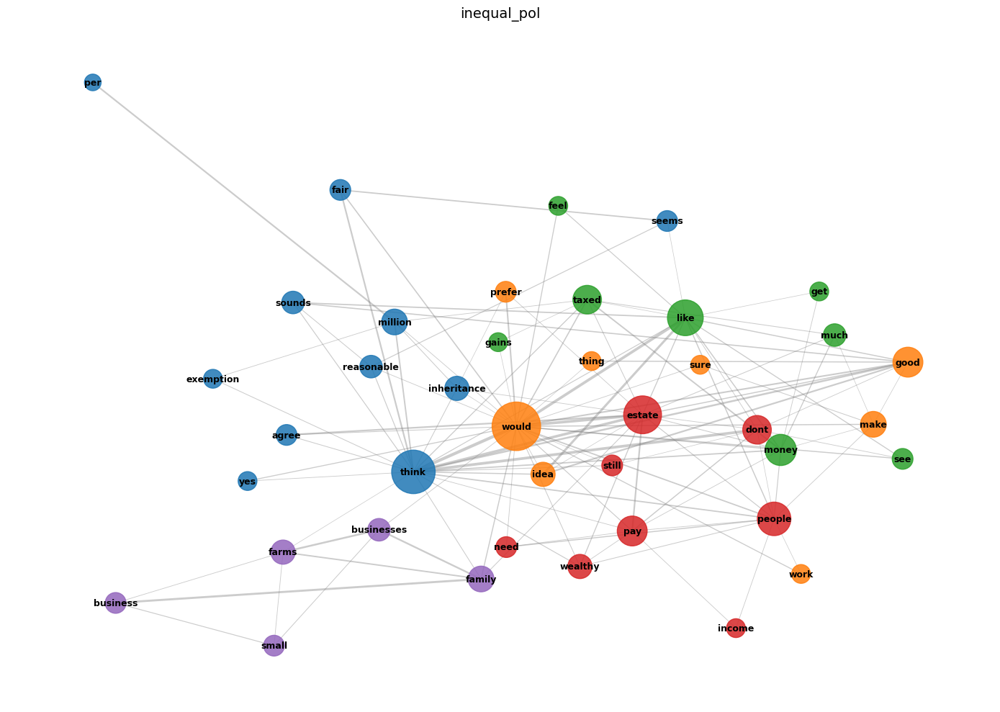

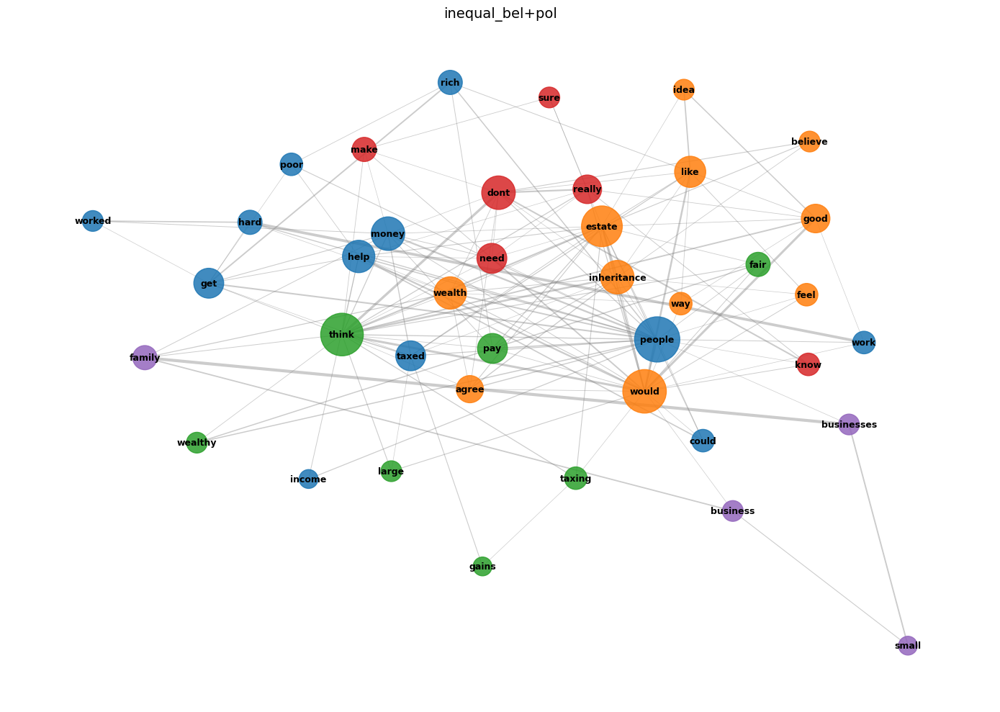

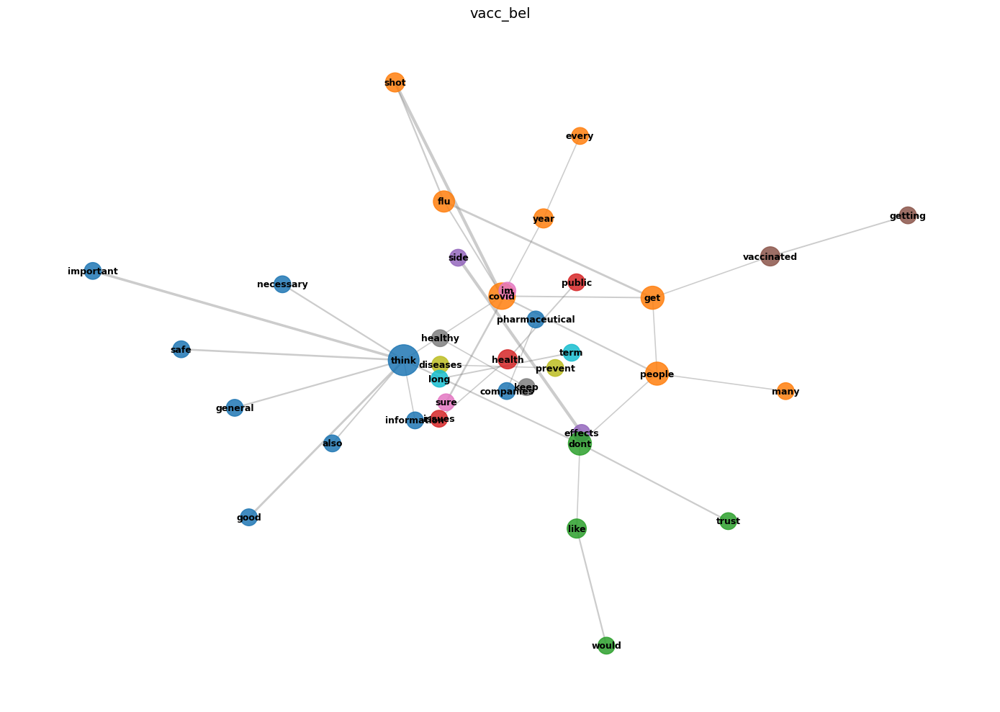

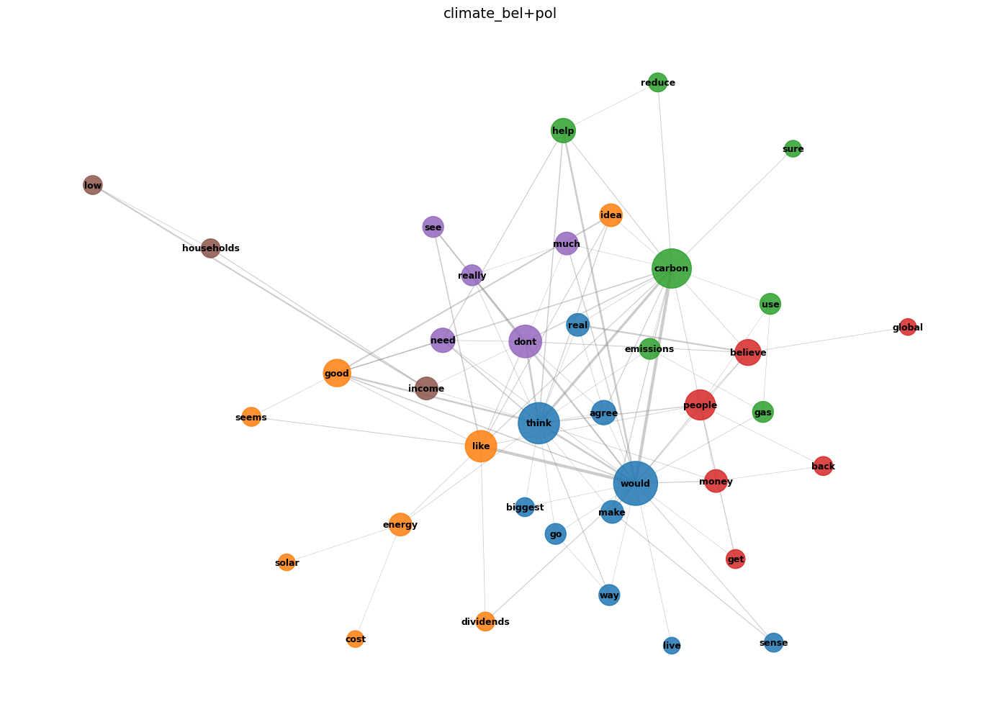

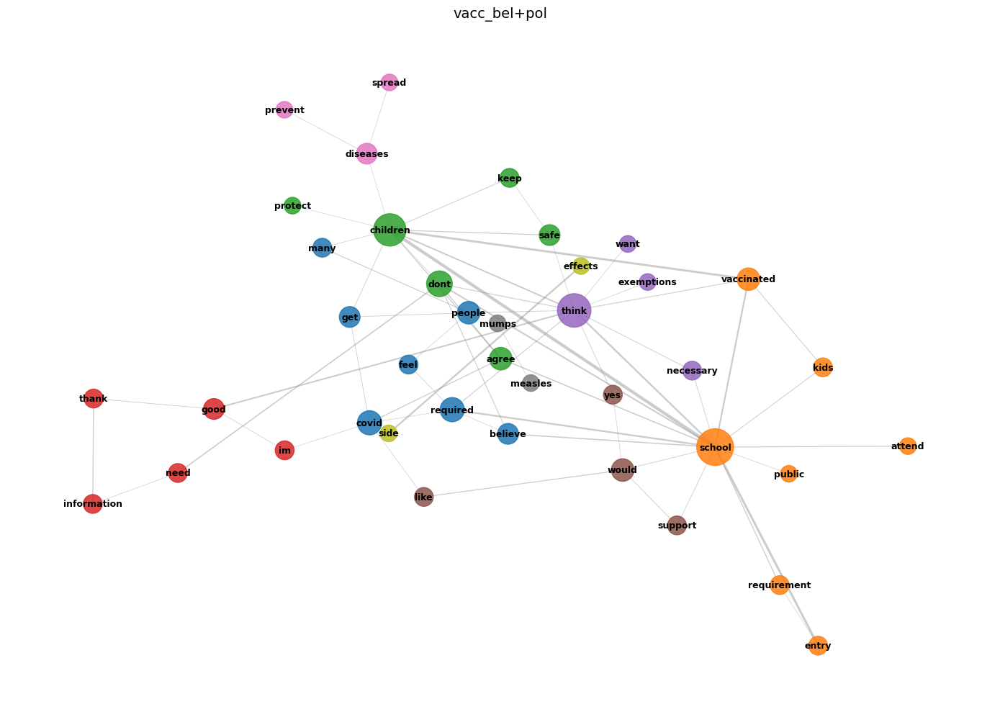

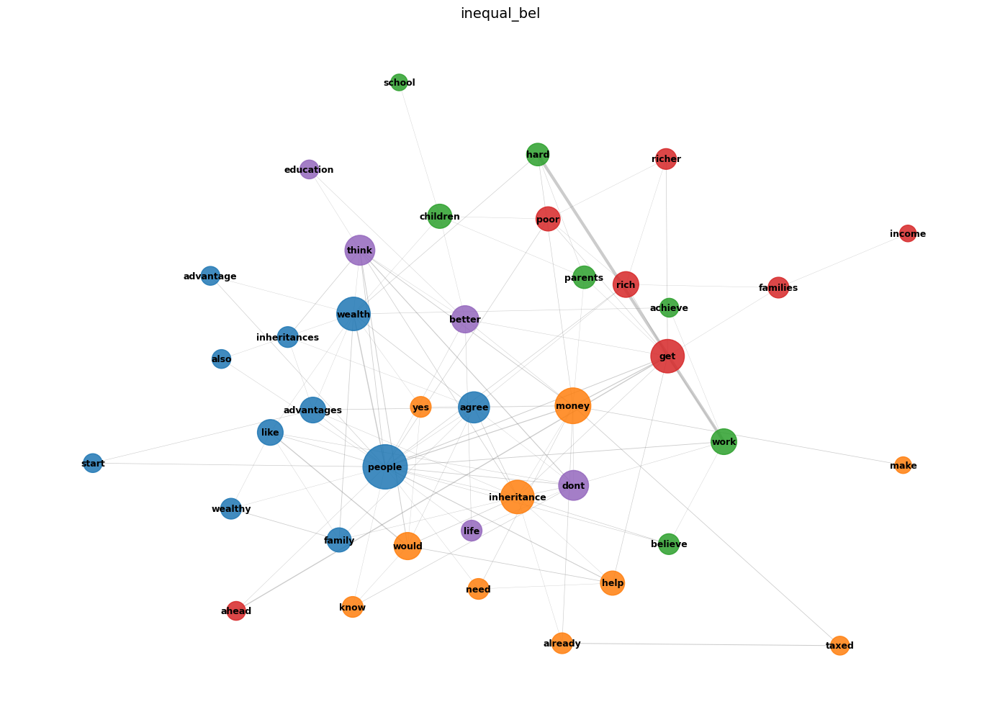

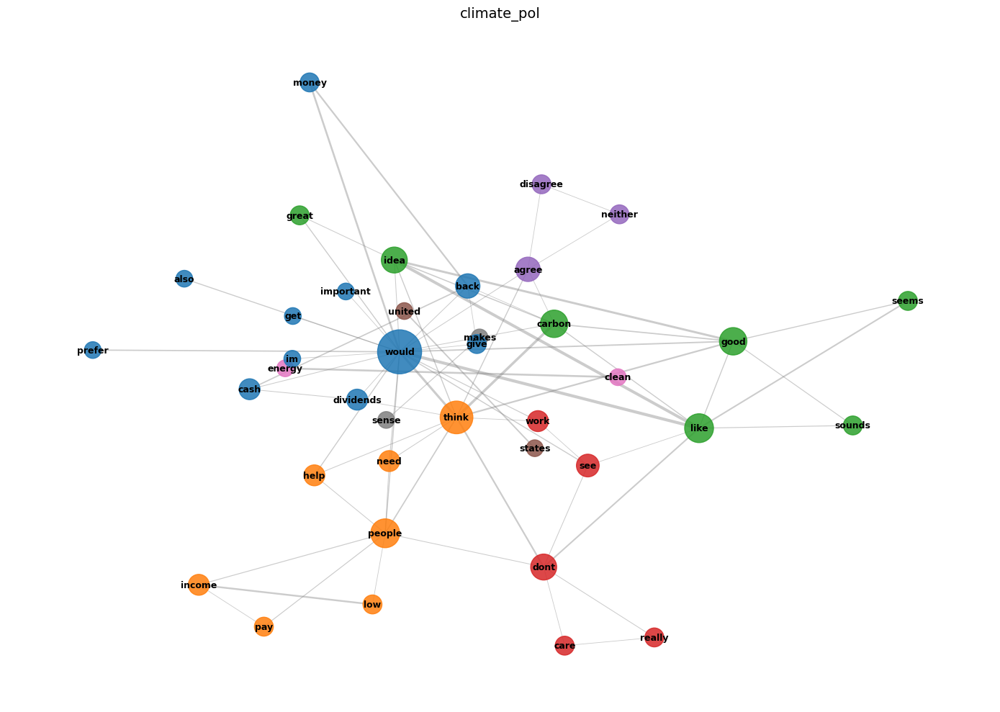

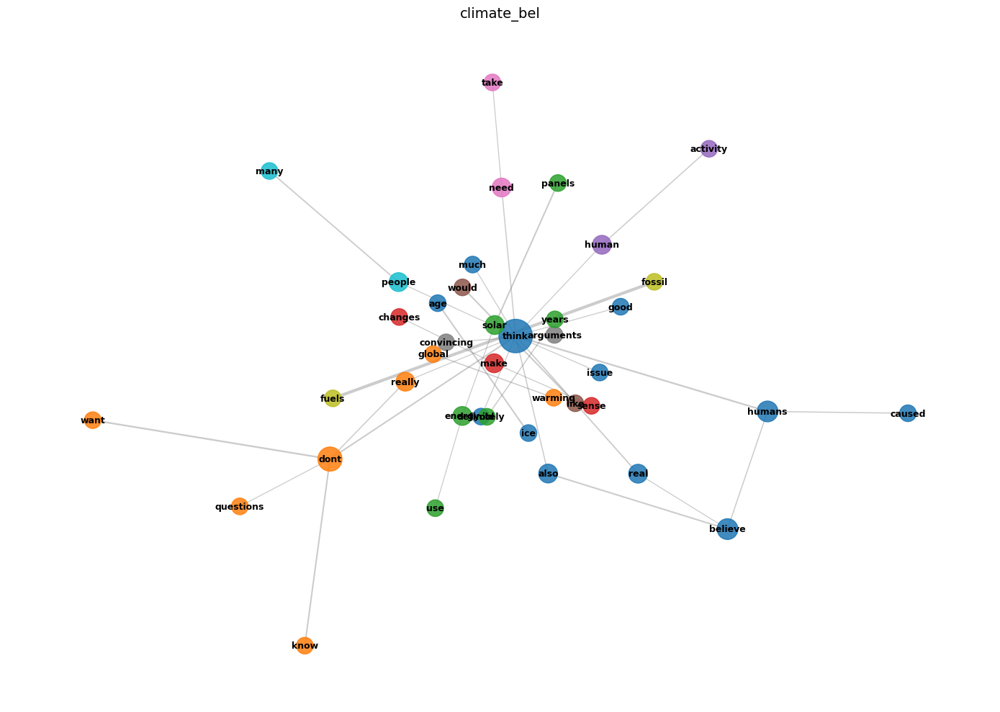

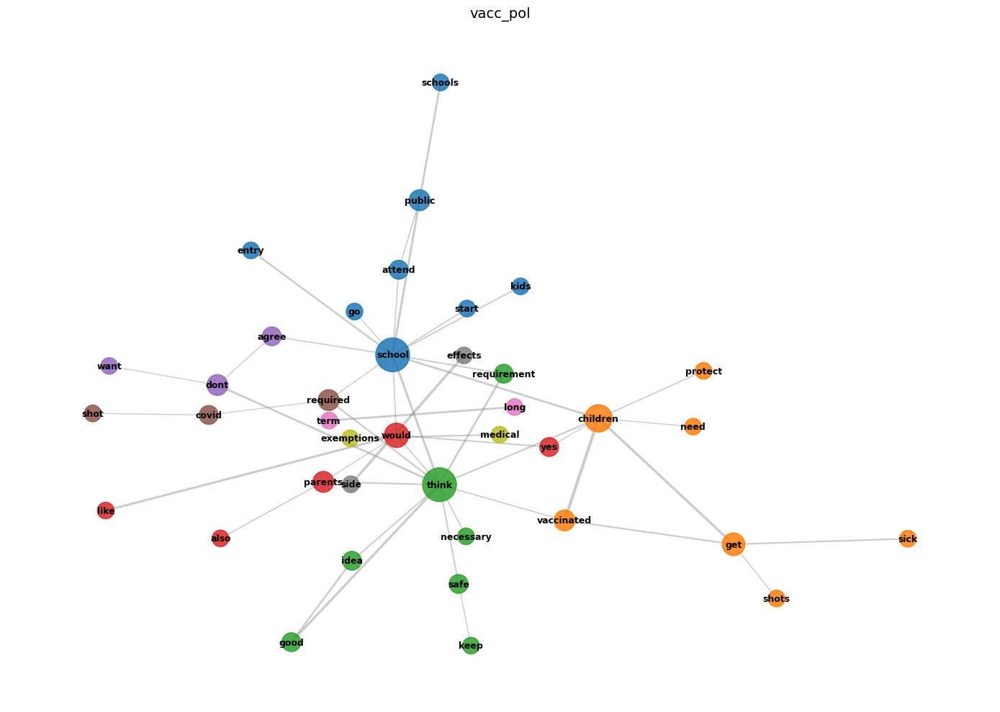

In [17]:
# building network graph
for topic, words in corpus.items():
    G = build_cooccurrence_network(words, window=2, min_edge_weight=5)
    plot_cooccurrence_network(G, title=topic)

# Analysis of Subgroup: People that write a lot in the first reply

In [18]:
# subset a df with people that have written more than 50 words in the first reply message
subset_many_words = df[df["word_count_user_round1"] > 50]
len(subset_many_words)

862

In [19]:
# using ony reply 1
reply_cols = ["userFirstReply"]
df["all_replies_1"] = df[reply_cols].fillna("").agg(" ".join, axis=1)

# building one corpus (i.e. list) per intervention condition
corpus = {}

for topic in df["condition"].unique():
    
    texts = df.loc[df["condition"] == topic, "all_replies_1"]
    
    combined_text = " ".join(texts)
    
    corpus[topic] = clean_text(combined_text)

In [20]:
# building one corpus (i.e. list) per intervention condition for subgroup 
corpus = {}

for topic in subset_df_big_effects["condition"].unique():
    
    texts = subset_df_big_effects.loc[subset_df_big_effects["condition"] == topic, "all_replies"]
    
    combined_text = " ".join(texts)
    
    corpus[topic] = clean_text(combined_text)


# extracting the most common words per condition
top_words = {}
bigram_corpus = {}

print("Most common words and bigrams per condition: ")
for topic, words in corpus.items():

    bigram_list = [" ".join(b) for b in bigrams(words)]
    bigram_corpus[topic] = bigram_list
    
    counter = Counter(words)
    bigram_counts = Counter(bigram_corpus[topic])

    top_words[topic] = counter.most_common(10)

    print("\n", topic)
    print(counter.most_common(10))
    print(bigram_counts.most_common(10))


Most common words and bigrams per condition: 

 inequal_pol
[('would', 291), ('estate', 195), ('think', 195), ('people', 124), ('money', 119), ('like', 118), ('dont', 99), ('good', 97), ('pay', 86), ('taxed', 85)]
[('dont think', 22), ('would like', 18), ('designed estate', 17), ('like idea', 16), ('good idea', 15), ('million per', 14), ('family business', 14), ('im sure', 14), ('united states', 13), ('would support', 13)]

 inequal_bel+pol
[('would', 247), ('think', 233), ('people', 213), ('estate', 176), ('wealth', 159), ('money', 150), ('inheritance', 133), ('like', 121), ('family', 114), ('dont', 110)]
[('dont think', 22), ('family businesses', 21), ('capital gains', 15), ('small businesses', 14), ('hard work', 14), ('makes sense', 13), ('sounds like', 13), ('work hard', 13), ('already taxed', 13), ('would need', 13)]

 vacc_bel
[('think', 83), ('covid', 78), ('get', 56), ('people', 53), ('dont', 53), ('like', 44), ('health', 36), ('believe', 35), ('one', 34), ('flu', 30)]
[('side 

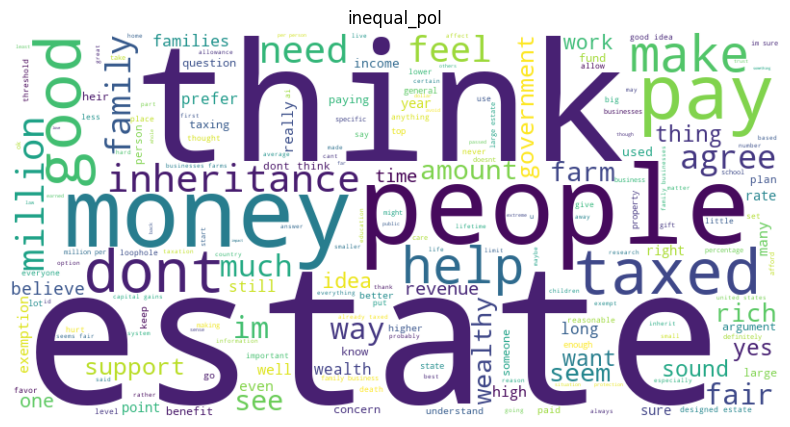

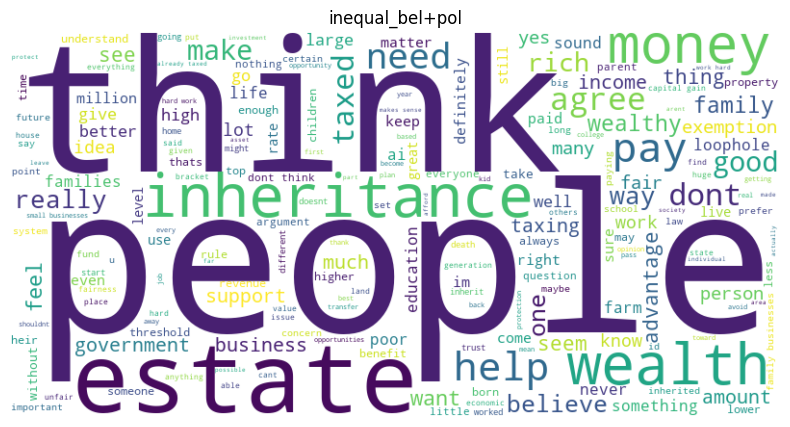

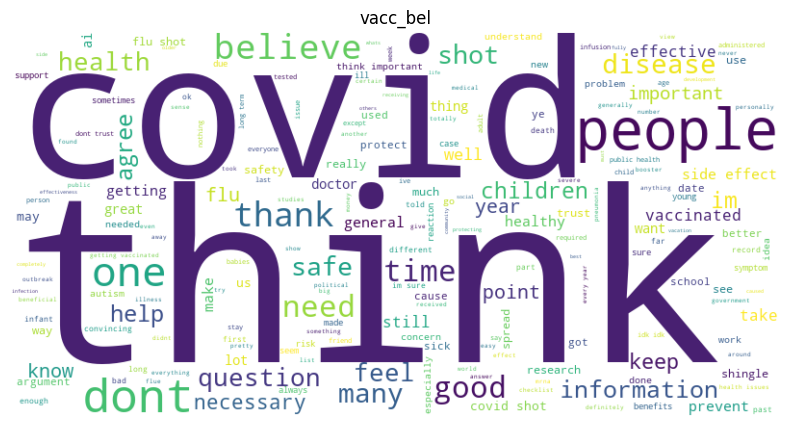

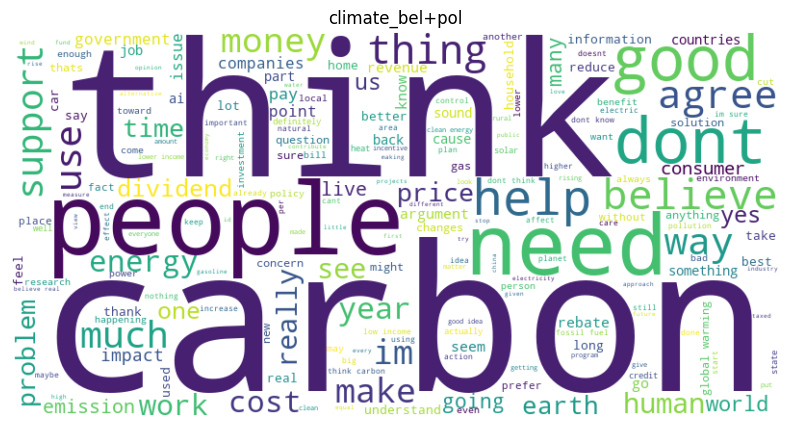

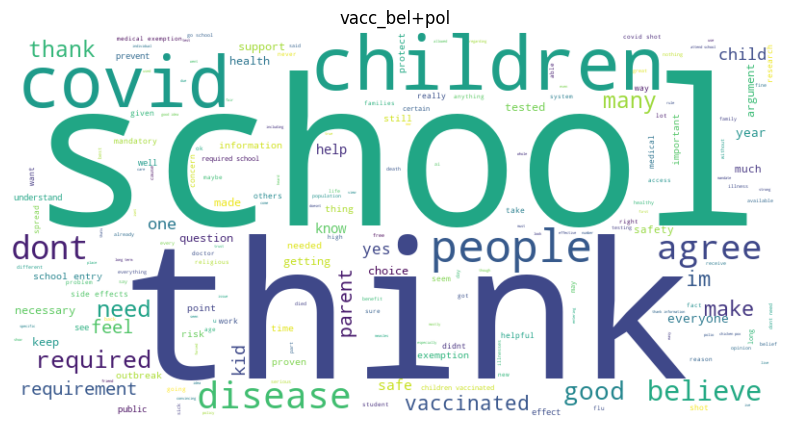

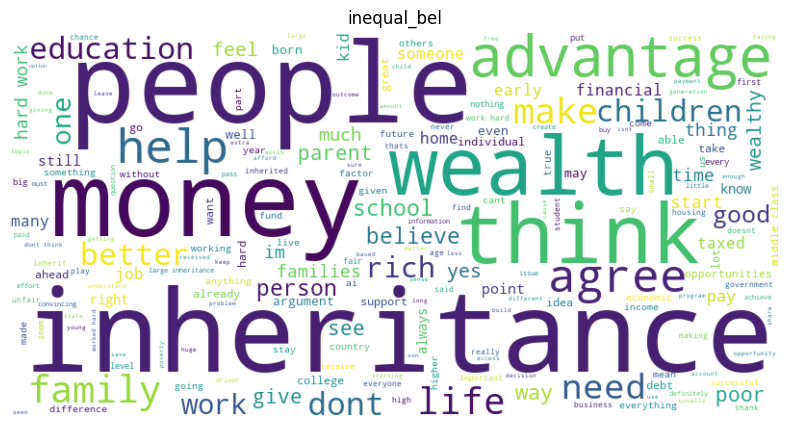

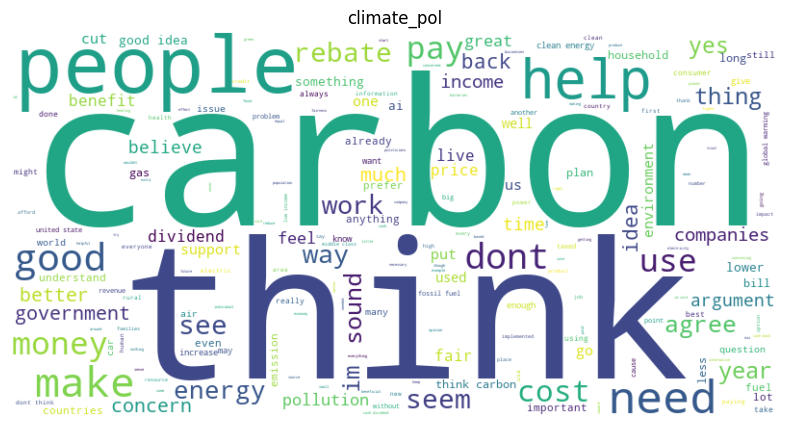

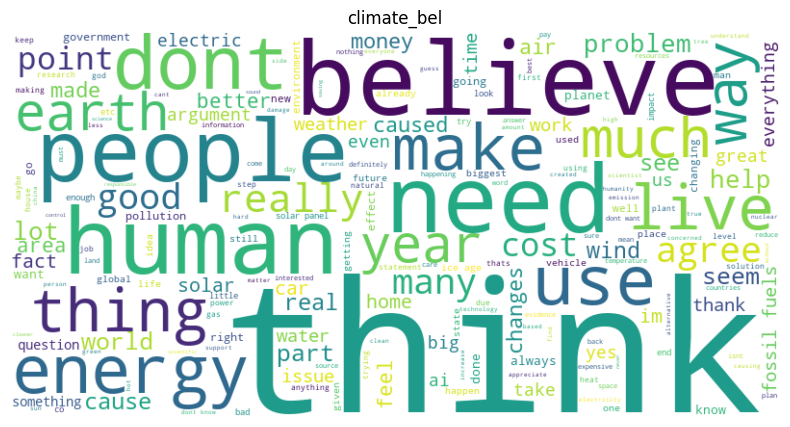

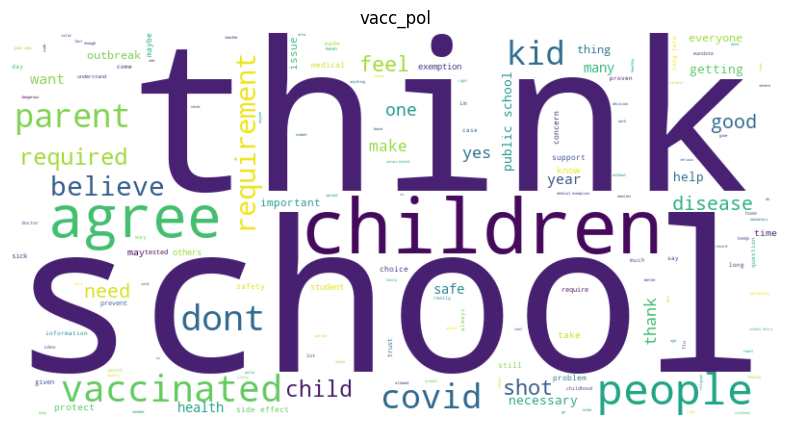

In [21]:
# creating a wordcloud per condition
for topic, words in corpus.items():

    text = " ".join(words)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        relative_scaling = 1, # means that words that are twice as frequent are displayed twoce as big
        collocations =  True,
        random_state=42
    ).generate(text)

    plt.figure(figsize=(10,5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(topic)
    plt.show()

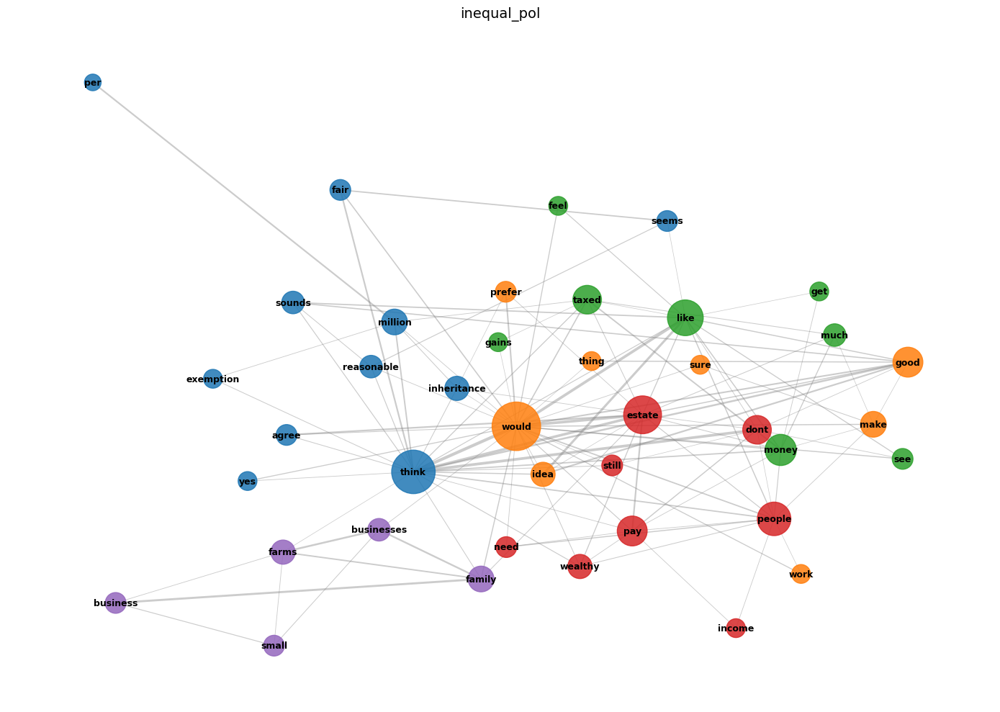

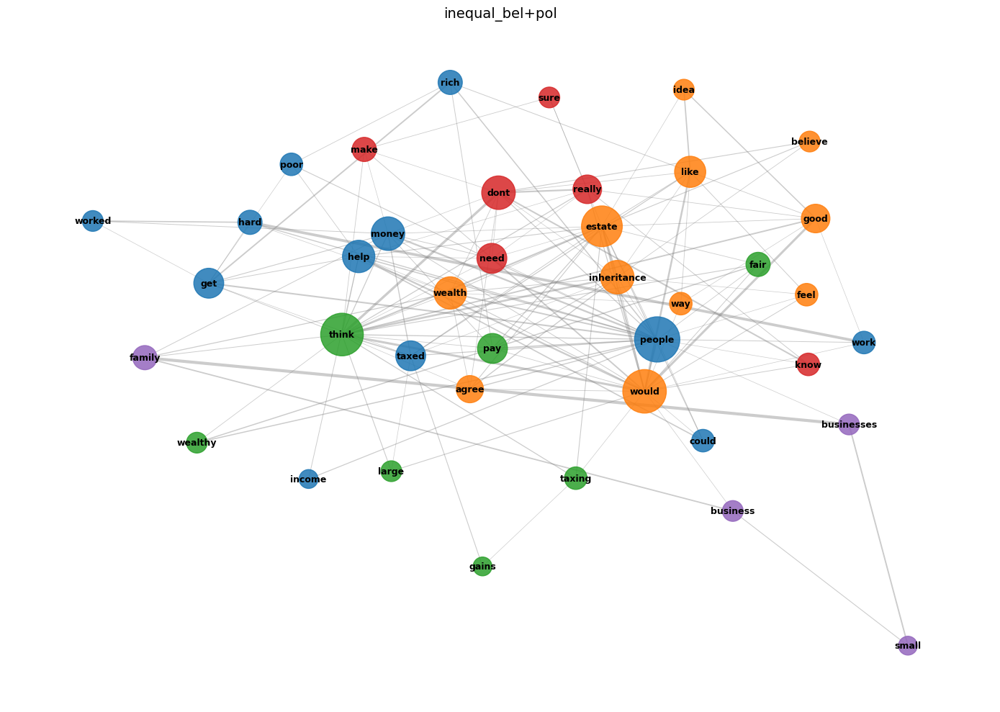

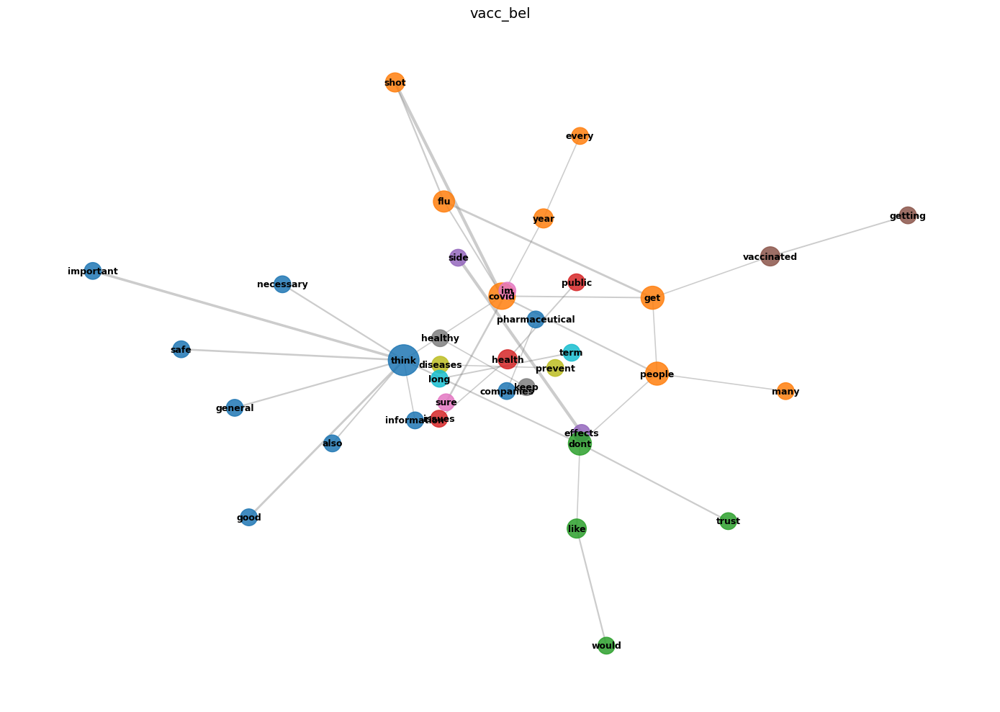

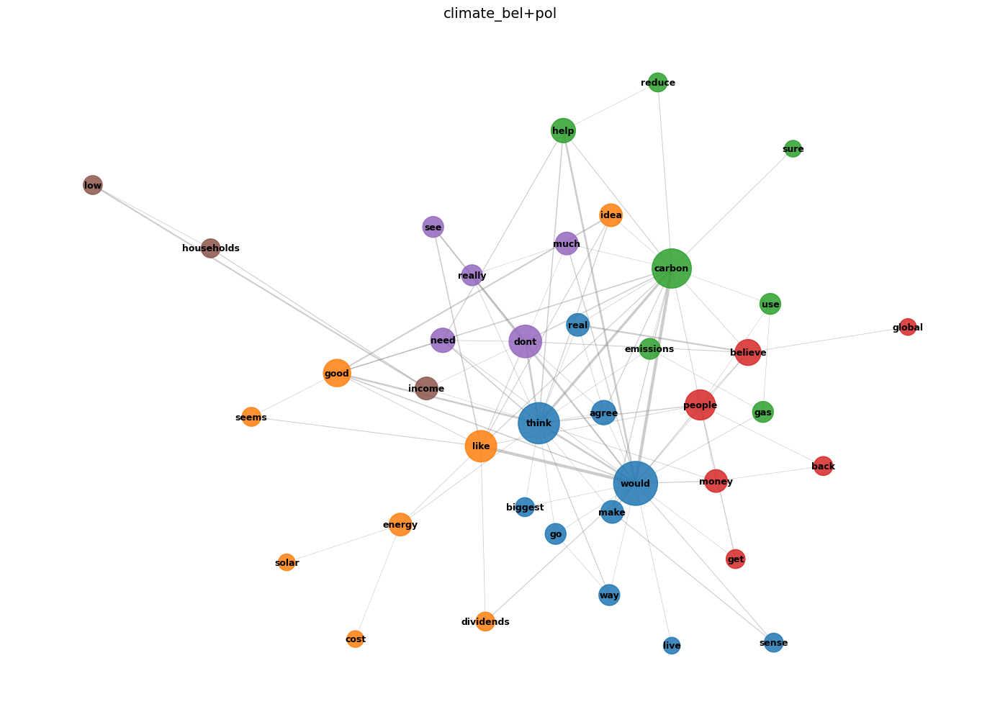

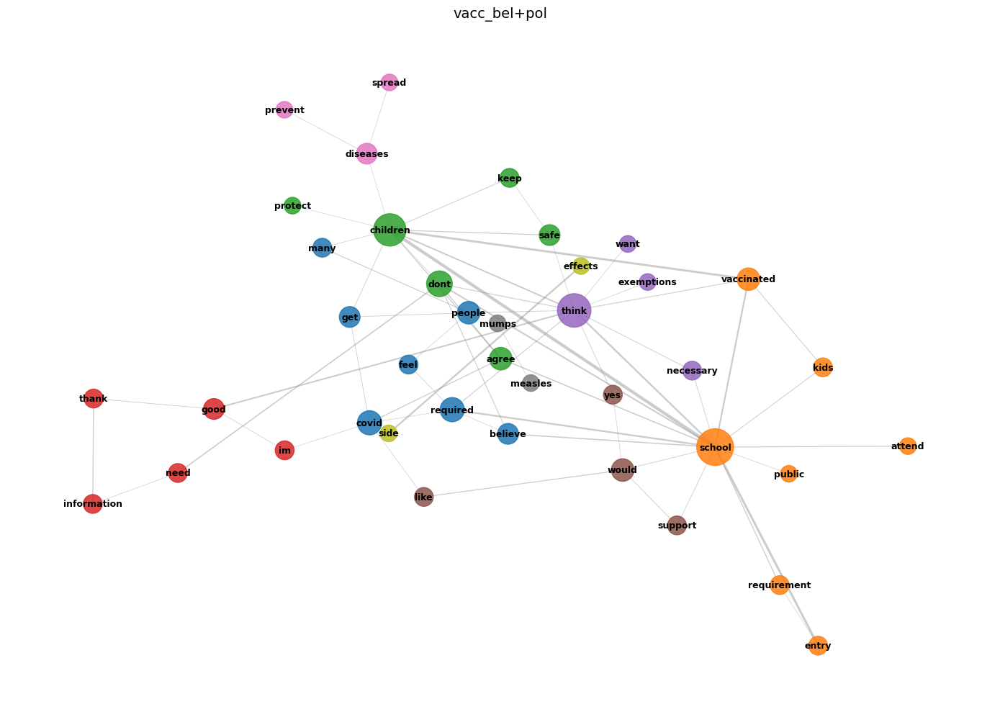

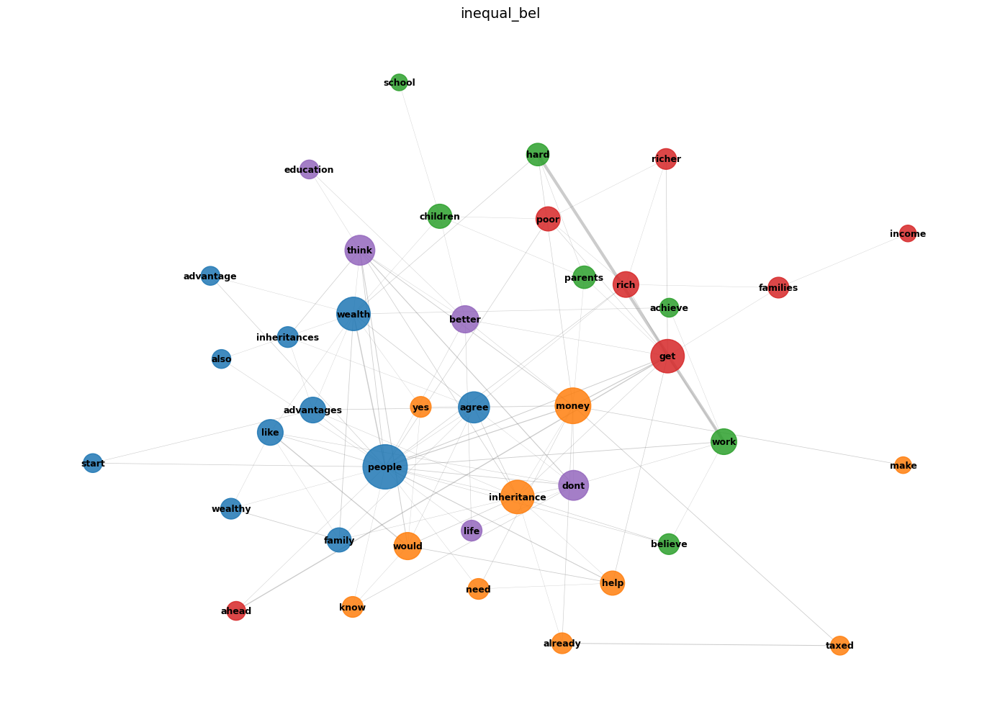

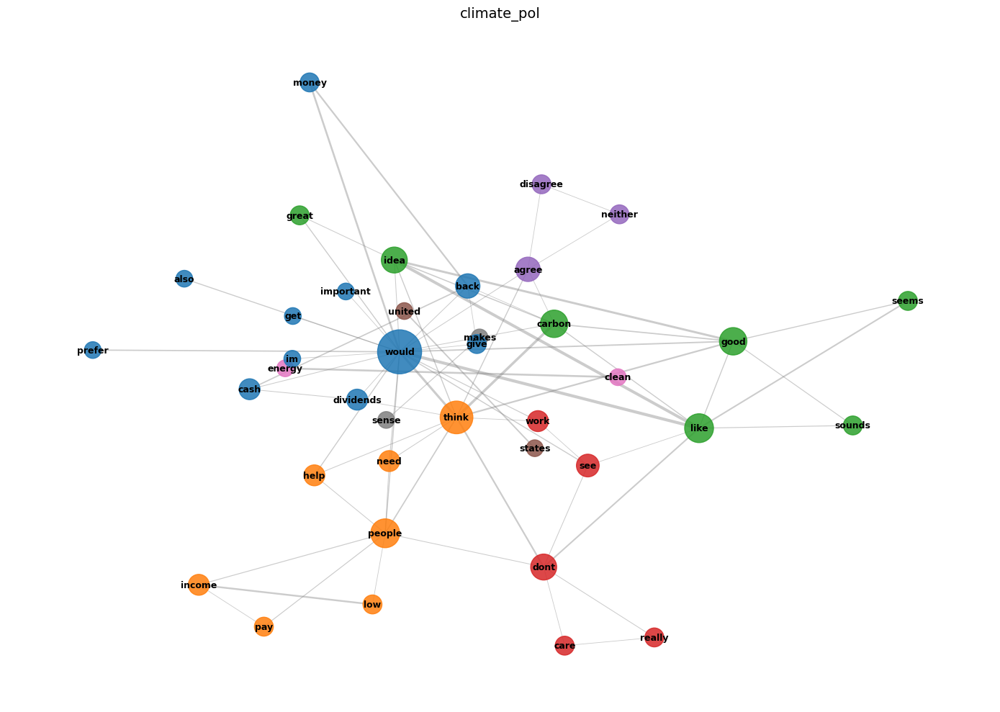

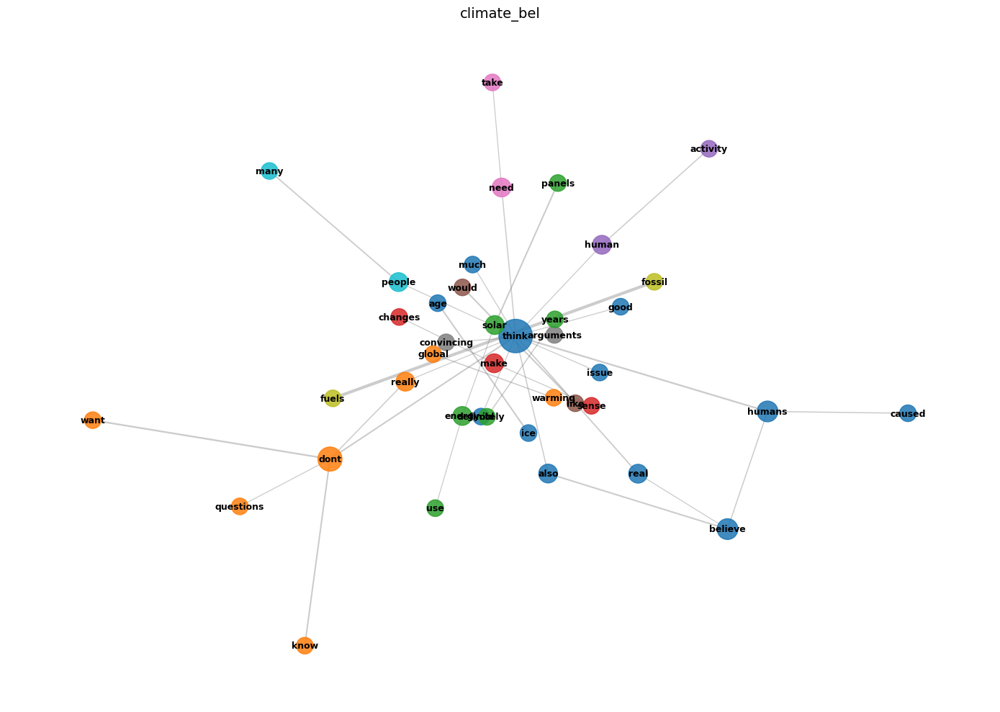

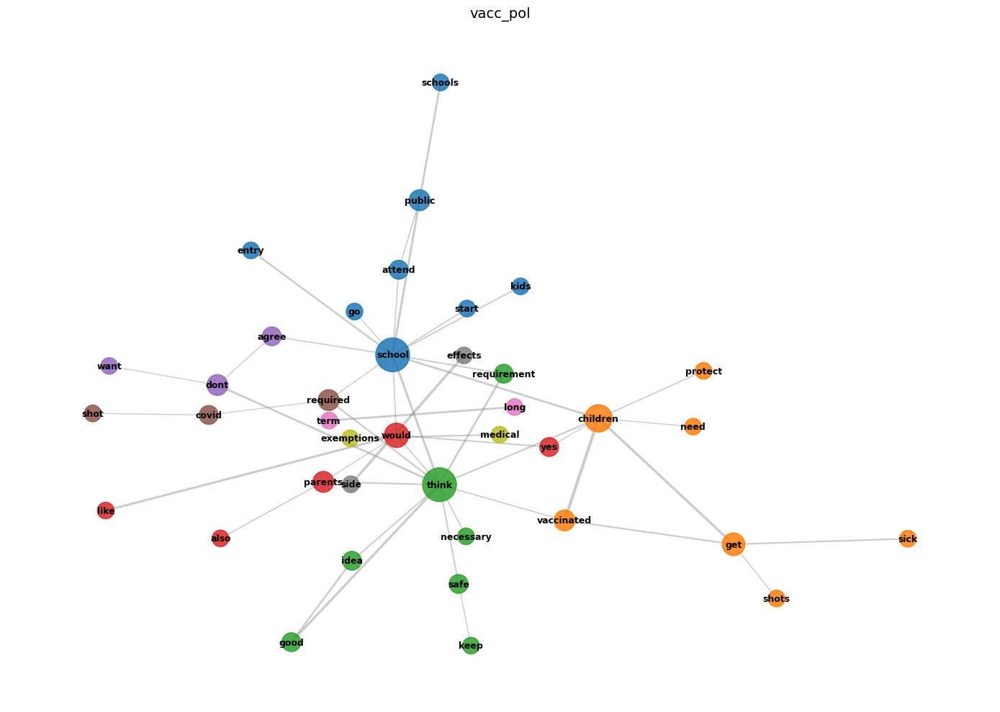

In [22]:
# building network graph
for topic, words in corpus.items():
    G = build_cooccurrence_network(words, window=2, min_edge_weight=5)
    plot_cooccurrence_network(G, title=topic)